# 7. Evaluación de modelos

## 7.1 Tabla maestra de las 140 combinaciones

Cada fila de la tabla maestra (`resultados/tabla_maestra.csv`) es una combinación con la media y la desviación estándar de sus métricas en los cinco pliegues externos, el número de evaluaciones, los tiempos, los hiperparámetros elegidos en cada pliegue y la semilla. El mapa de calor muestra, para cada par modelo-balanceo, el mejor AUC-PR externo entre los optimizadores.

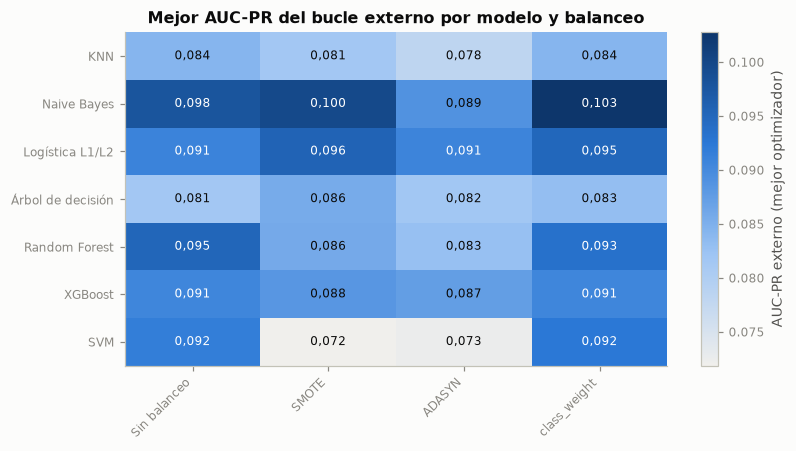

modelo,balanceo,optimizador,AUC-PR media,AUC-PR DE,AUC media,Recall media,F1 media,Tiempo (min),Evaluaciones
Naive Bayes,class_weight,Bayesiana (Optuna TPE),"0,1028","0,1081","0,5368","0,8498","0,1443","2,5239",100
Naive Bayes,SMOTE,Genético (DEAP),"0,0997","0,0955","0,5405","0,8120","0,1432","2,7966",100
Naive Bayes,SMOTE,Random Search,"0,0997","0,0958","0,5405","0,7967","0,1466","2,8013",100
Naive Bayes,SMOTE,Bayesiana (Optuna TPE),"0,0997","0,0953","0,5407","0,8086","0,1432","2,8029",100
Naive Bayes,Sin balanceo,Grid Search,"0,0978","0,0932","0,5340","0,0438","0,0511","2,6944",100
Naive Bayes,class_weight,Grid Search,"0,0978","0,0933","0,5340","0,7060","0,1065","2,5203",100
Naive Bayes,Sin balanceo,Genético (DEAP),"0,0976","0,0936","0,5321","0,0511","0,0540","2,6325",100
Naive Bayes,class_weight,Genético (DEAP),"0,0973","0,0939","0,5312","0,6658","0,1068","2,5828",100
Logística L1/L2,SMOTE,Random Search,"0,0955","0,0956","0,5213","0,7053","0,1323","9,5666",100
Random Forest,Sin balanceo,Bayesiana (Optuna TPE),"0,0952","0,0921","0,5379","0,0000","0,0000","23,5223",100


modelo,optimizador,RMSE media (log),RMSE DE,MAE media (log),R² media,RMSE media (s)
XGBoost,Bayesiana (Optuna TPE),"0,9060","0,0326","0,7130","0,0198","270,3610"
XGBoost,Random Search,"0,9062","0,0327","0,7138","0,0194","270,6820"
XGBoost,Grid Search,"0,9068","0,0331","0,7135","0,0181","270,6955"
XGBoost,Genético (DEAP),"0,9079","0,0344","0,7136","0,0158","270,6281"
Random Forest,Random Search,"0,9080","0,0331","0,7143","0,0156","270,4630"
Random Forest,Grid Search,"0,9082","0,0345","0,7141","0,0153","270,6833"
Random Forest,Genético (DEAP),"0,9083","0,0330","0,7146","0,0150","270,5584"
Random Forest,Bayesiana (Optuna TPE),"0,9094","0,0344","0,7147","0,0125","270,4607"


AUC externo por modelo y pliegue (máximo entre balanceos y optimizadores)


pliegue,Pliegue 1 (2008-06),Pliegue 2 (2008-07),Pliegue 3 (2008-08),Pliegue 4 (2008-11),Pliegue 5 (2009-05)
modelo,,,,,
KNN,"0,499","0,535","0,521","0,487","0,619"
Naive Bayes,"0,526","0,509","0,515","0,486","0,716"
Logística L1/L2,"0,518","0,511","0,499","0,469","0,681"
Árbol de decisión,"0,533","0,512","0,526","0,499","0,658"
Random Forest,"0,522","0,535","0,543","0,491","0,679"
XGBoost,"0,527","0,523","0,529","0,517","0,656"
SVM,"0,530","0,530","0,511","0,473","0,673"


AUC-PR externo por modelo y pliegue (máximo entre balanceos y optimizadores)


pliegue,Pliegue 1 (2008-06),Pliegue 2 (2008-07),Pliegue 3 (2008-08),Pliegue 4 (2008-11),Pliegue 5 (2009-05)
modelo,,,,,
KNN,"0,042","0,069","0,065","0,053","0,203"
Naive Bayes,"0,046","0,062","0,066","0,058","0,296"
Logística L1/L2,"0,041","0,064","0,064","0,054","0,266"
Árbol de decisión,"0,043","0,068","0,064","0,054","0,215"
Random Forest,"0,044","0,068","0,070","0,054","0,259"
XGBoost,"0,045","0,064","0,066","0,058","0,231"
SVM,"0,043","0,064","0,065","0,050","0,255"


**Interpretación.** La mejor combinación de clasificación por AUC-PR externo medio es Naive Bayes · class_weight · Bayesiana (Optuna TPE), con 0,1028 ± 0,1081 y un AUC medio de 0,5368. Pliegue por pliegue, en los cuatro que validan dentro de 2008 el mejor AUC de cada modelo va de 0,469 a 0,543, mientras que en el último (Pliegue 5 (2009-05)) va de 0,619 (KNN) a 0,716 (Naive Bayes). En regresión, el mejor RMSE medio es 0,9060 con un R² medio de 0,020.

Esto significa que dentro de 2008 ningún modelo ordena a los clientes mejor que el azar con información previa a la llamada: la señal aparece al validar en 2009, cuando las variables macroeconómicas y de calendario marcan un régimen distinto. Por eso el promedio de los cinco pliegues queda cerca del azar y el orden entre combinaciones lo decide casi por completo el último pliegue. En ese pliegue los modelos más simples (Naive Bayes, la logística) igualan o superan a los más flexibles, porque extrapolan con menos varianza a un régimen que no vieron, el mismo patrón que mostró la sección 4.11 del Entregable 2. En regresión, un R² cercano a cero confirma lo anticipado en la sección 3.8.1.

Por tanto, corresponde mantener el esquema de validación tal como se declaró antes de ver los resultados (cambiarlo ahora sería *data snooping*), leer las métricas del bucle externo como una estimación conservadora, contrastar con el conjunto de prueba (2009-2010, sección 7.3) y decidir con pruebas estadísticas que incluyan bloques mensuales, con más potencia que cinco pliegues (sección 8.1).

In [61]:
m_clf = maestra[maestra["tarea"] == "clf"].copy()
m_reg = maestra[maestra["tarea"] == "reg"].copy()
mapa = m_clf.pivot_table(index="modelo", columns="balanceo", values="auc_pr_media", aggfunc="max")
mapa = mapa.loc[cfg.MODELOS_CLF, cfg.BALANCEOS]
fig, ax = plt.subplots(figsize=(7.5, 4.2))
im = mapa_calor(ax, mapa.to_numpy(), [NM[m_] for m_ in mapa.index], [NB[b_] for b_ in mapa.columns], CMAP_SEQ,
                mapa.min().min(), mapa.max().max(), dec=3, tam=8)
fig.colorbar(im, ax=ax, label="AUC-PR externo (mejor optimizador)")
ax.set_title("Mejor AUC-PR del bucle externo por modelo y balanceo")
plt.tight_layout()
plt.show()

cols = ["modelo", "balanceo", "optimizador", "auc_pr_media", "auc_pr_de", "auc_media", "recall_media", "f1_media",
        "t_opt_total", "n_eval_total"]
top = m_clf.sort_values("auc_pr_media", ascending=False)[cols].head(12).copy()
top["modelo"], top["balanceo"], top["optimizador"] = top["modelo"].map(NM), top["balanceo"].map(NB), top["optimizador"].map(NO)
top["t_opt_total"] = top["t_opt_total"] / 60
tabla(top.rename(columns={"auc_pr_media": "AUC-PR media", "auc_pr_de": "AUC-PR DE", "auc_media": "AUC media",
                          "recall_media": "Recall media", "f1_media": "F1 media", "t_opt_total": "Tiempo (min)",
                          "n_eval_total": "Evaluaciones"}), dec=4, indice=False)
topr = m_reg.sort_values("rmse_media")[["modelo", "optimizador", "rmse_media", "rmse_de", "mae_media", "r2_media",
                                         "rmse_seg_media"]].head(8).copy()
topr["modelo"], topr["optimizador"] = topr["modelo"].map(NM), topr["optimizador"].map(NO)
tabla(topr.rename(columns={"rmse_media": "RMSE media (log)", "rmse_de": "RMSE DE", "mae_media": "MAE media (log)",
                           "r2_media": "R² media", "rmse_seg_media": "RMSE media (s)"}), dec=4, indice=False)

por_pliegue = {met: clf_pl.pivot_table(index="modelo", columns="pliegue", values=met, aggfunc="max")
               .loc[cfg.MODELOS_CLF].rename(index=NM, columns=lambda k: f"Pliegue {k + 1} ({esquema_anidado['Valida hasta'].iloc[k]})")
               for met in ("auc", "auc_pr")}
print("AUC externo por modelo y pliegue (máximo entre balanceos y optimizadores)")
tabla(por_pliegue["auc"], dec=3)
print("AUC-PR externo por modelo y pliegue (máximo entre balanceos y optimizadores)")
tabla(por_pliegue["auc_pr"], dec=3)
exportar("auc_por_pliegue", por_pliegue["auc"].reset_index(names="Modelo"))

mejor_c = m_clf.loc[m_clf["auc_pr_media"].idxmax()]
auc_p = por_pliegue["auc"]
ult = auc_p.columns[-1]
interpretar(
    f"La mejor combinación de clasificación por AUC-PR externo medio es {etiqueta(mejor_c)}, con "
    f"{num(mejor_c['auc_pr_media'], 4)} ± {num(mejor_c['auc_pr_de'], 4)} y un AUC medio de "
    f"{num(mejor_c['auc_media'], 4)}. Pliegue por pliegue, en los cuatro que validan dentro de 2008 el mejor AUC de "
    f"cada modelo va de {num(auc_p.iloc[:, :-1].min().min(), 3)} a {num(auc_p.iloc[:, :-1].max().max(), 3)}, mientras "
    f"que en el último ({ult}) va de {num(auc_p[ult].min(), 3)} ({auc_p[ult].idxmin()}) a {num(auc_p[ult].max(), 3)} "
    f"({auc_p[ult].idxmax()}). En regresión, el mejor RMSE medio es {num(m_reg['rmse_media'].min(), 4)} con un R² medio "
    f"de {num(m_reg.loc[m_reg['rmse_media'].idxmin(), 'r2_media'], 3)}.",
    conectar("Esto significa que", "Dentro de 2008 ningún modelo ordena a los clientes mejor que el azar con información "
             "previa a la llamada: la señal aparece al validar en 2009, cuando las variables macroeconómicas y de "
             "calendario marcan un régimen distinto. Por eso el promedio de los cinco pliegues queda cerca del azar y "
             "el orden entre combinaciones lo decide casi por completo el último pliegue. En ese pliegue los modelos "
             "más simples (Naive Bayes, la logística) igualan o superan a los más flexibles, porque extrapolan con menos "
             "varianza a un régimen que no vieron, el mismo patrón que mostró la sección 4.11 del Entregable 2. En "
             "regresión, un R² cercano a cero confirma lo anticipado en la sección 3.8.1."),
    conectar("Por tanto, corresponde", "Mantener el esquema de validación tal como se declaró antes de ver los resultados "
             "(cambiarlo ahora sería *data snooping*), leer las métricas del bucle externo como una estimación "
             "conservadora, contrastar con el conjunto de prueba (2009-2010, sección 7.3) y decidir con pruebas "
             "estadísticas que incluyan bloques mensuales, con más potencia que cinco pliegues (sección 8.1)."))

exportar("maestra", maestra.drop(columns=["params_por_pliegue"]).assign(
    Modelo=lambda d: d["modelo"].map(NM), Balanceo=lambda d: d["balanceo"].map(NB),
    Optimizador=lambda d: d["optimizador"].map(NO)))
exportar("mapa_balanceo", mapa.rename(index=NM, columns=NB).reset_index())


## 7.2 Balanceo de clases: SMOTE, ADASYN y `class_weight`

**SMOTE** genera ejemplos sintéticos de la clase minoritaria interpolando entre un positivo y uno de sus k = 5 vecinos positivos. **ADASYN** hace lo mismo pero genera más ejemplos alrededor de los positivos más difíciles, los que tienen más vecinos negativos. **`class_weight='balanced'`** no crea datos: pondera la pérdida con el inverso de la frecuencia de cada clase. En KNN, Naive Bayes y XGBoost, que no aceptan `class_weight`, se usan equivalentes exactos: votos ponderados por clase, priors iguales y `scale_pos_weight = n_negativos / n_positivos` (`src/bm/modelos.py`). Los sobremuestreos se aplican después del *one-hot*, de modo que los ejemplos sintéticos pueden tener valores intermedios en columnas binarias; SMOTE-NC evitaría ese efecto, pero no está en la guía y se deja como limitación.

El efecto se mide promediando cada métrica sobre optimizadores y pliegues, y probando cada técnica contra "sin balanceo" con Wilcoxon por bloques (modelo, optimizador, pliegue), ajuste de Holm y delta de Cliff.

,AUC-PR,AUC,Recall,Precision,F1,Brier
Sin balanceo,"0,0866","0,5190","0,0470","0,0463","0,0324","0,0811"
SMOTE,"0,0843","0,5161","0,4031","0,0760","0,1032","0,2700"
ADASYN,"0,0811","0,5095","0,3922","0,0764","0,0867","0,2652"
class_weight,"0,0864","0,5159","0,5160","0,0835","0,1193","0,2980"


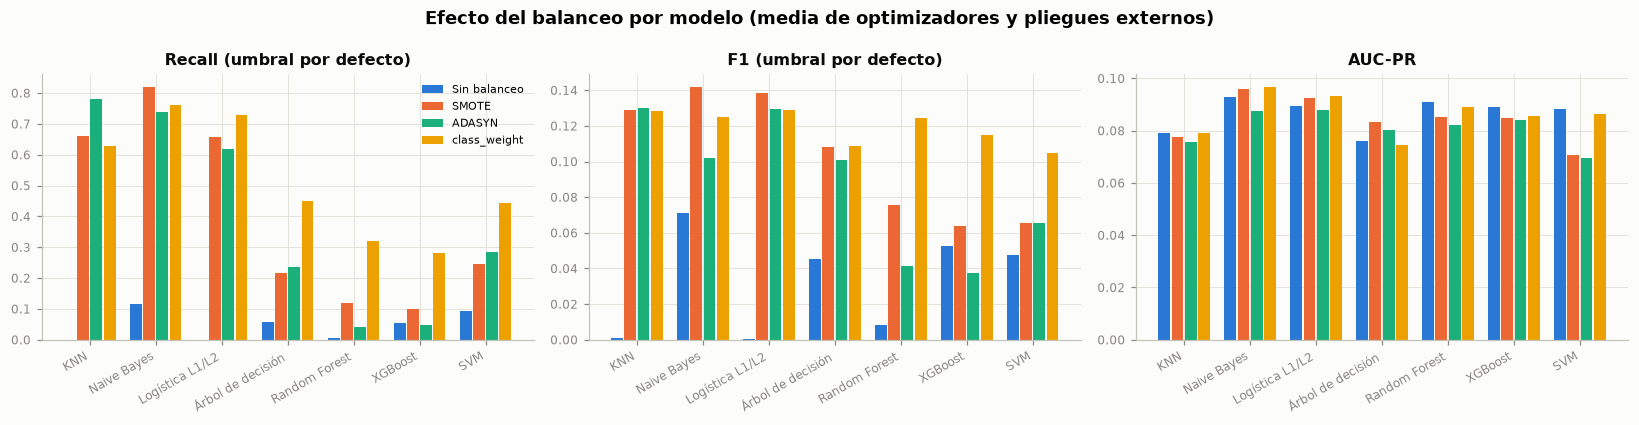

Técnica,Métrica,Diferencia media vs sin balanceo,p crudo,delta de Cliff,p Holm,Magnitud
SMOTE,recall,"0,3562","< 0,001","0,7862","< 0,001",grande
SMOTE,f1,"0,0708","< 0,001","0,6931","< 0,001",grande
SMOTE,auc_pr,"-0,0023","0,520","-0,0040","0,896",despreciable
SMOTE,brier,"0,1889","< 0,001","0,8037","< 0,001",grande
ADASYN,recall,"0,3452","< 0,001","0,7510","< 0,001",grande
ADASYN,f1,"0,0543","< 0,001","0,6558","< 0,001",grande
ADASYN,auc_pr,"-0,0055","0,029","-0,0186","0,087",despreciable
ADASYN,brier,"0,1841","< 0,001","0,7965","< 0,001",grande
class_weight,recall,"0,4691","< 0,001","0,9114","< 0,001",grande
class_weight,f1,"0,0869","< 0,001","0,7851","< 0,001",grande


**Interpretación.** Sin balanceo, el recall medio con el umbral por defecto es 0,047; con SMOTE sube a 0,403, con ADASYN a 0,392 y con class_weight a 0,516. El F1 pasa de 0,032 a 0,103, 0,087 y 0,119, mientras que el AUC-PR cambia en -0,0023, -0,0055 y -0,0002 y el Brier sube de 0,081 a 0,270, 0,265 y 0,298.

Esto significa que el balanceo funciona como un desplazamiento del umbral: al igualar las clases en el ajuste, las probabilidades suben y con el umbral de 0,5 se marcan más clientes, lo que eleva el recall y el F1. No mejora el orden de los clientes (el AUC-PR casi no cambia o baja) y empeora la calibración, porque las probabilidades dejan de reflejar la tasa real.

Por tal motivo, se opta por elegir el balanceo por el punto de operación que necesita el negocio y no por la discriminación: si el objetivo es encontrar más suscriptores con el umbral por defecto, class_weight logra el aumento de recall sin crear datos sintéticos; si se necesitan probabilidades para estimar el número esperado de suscripciones, conviene no balancear o recalibrar (sección 7.4).

In [62]:
met_bal = ["auc_pr", "auc", "recall", "precision", "f1", "brier"]
clf_n = clf_pl[clf_pl["optimizador"].isin(NUCLEO)]
bal = clf_n.groupby("balanceo")[met_bal].mean().loc[cfg.BALANCEOS]
bal.index = [NB[b_] for b_ in bal.index]
tabla(bal.rename(columns={"auc_pr": "AUC-PR", "auc": "AUC", "recall": "Recall", "precision": "Precision", "f1": "F1",
                          "brier": "Brier"}), dec=4)

fig, axs = plt.subplots(1, 3, figsize=(15, 3.9), sharey=False)
anchura = 0.2
for ax, met in zip(axs, ["recall", "f1", "auc_pr"]):
    g = clf_n.groupby(["modelo", "balanceo"])[met].mean().unstack().loc[cfg.MODELOS_CLF, cfg.BALANCEOS]
    x = np.arange(len(g))
    for j, b_ in enumerate(cfg.BALANCEOS):
        ax.bar(x + (j - 1.5) * anchura, g[b_], width=anchura - 0.02, color=COLOR_BAL[b_], label=NB[b_])
    ax.set_xticks(x, [NM[m_] for m_ in g.index], rotation=30, ha="right", fontsize=8)
    ax.set_title({"recall": "Recall (umbral por defecto)", "f1": "F1 (umbral por defecto)", "auc_pr": "AUC-PR"}[met])
axs[0].legend(fontsize=7)
fig.suptitle("Efecto del balanceo por modelo (media de optimizadores y pliegues externos)")
plt.tight_layout()
plt.show()

filas = []
for b_ in ["smote", "adasyn", "class_weight"]:
    for met in ["recall", "f1", "auc_pr", "brier"]:
        M = clf_n.pivot_table(index=["modelo", "optimizador", "pliegue"], columns="balanceo", values=met).dropna(
            subset=[b_, "ninguno"])
        w = wilcoxon(M[b_], M["ninguno"])
        filas.append({"Técnica": NB[b_], "Métrica": met, "Diferencia media vs sin balanceo": (M[b_] - M["ninguno"]).mean(),
                      "p crudo": w.pvalue, "delta de Cliff": st.delta_cliff(M[b_], M["ninguno"])})
pb = pd.DataFrame(filas)
pb["p Holm"] = st.ajustar_p(pb["p crudo"], "holm")
pb["Magnitud"] = pb["delta de Cliff"].apply(st.magnitud_cliff)
tabla(pb.assign(**{"p crudo": pb["p crudo"].map(pval), "p Holm": pb["p Holm"].map(pval)}), dec=4, indice=False)

r_ = pb.set_index(["Técnica", "Métrica"])
interpretar(
    f"Sin balanceo, el recall medio con el umbral por defecto es {num(bal.loc['Sin balanceo', 'recall'], 3)}; con SMOTE "
    f"sube a {num(bal.loc['SMOTE', 'recall'], 3)}, con ADASYN a {num(bal.loc['ADASYN', 'recall'], 3)} y con class_weight "
    f"a {num(bal.loc['class_weight', 'recall'], 3)}. El F1 pasa de {num(bal.loc['Sin balanceo', 'f1'], 3)} a "
    f"{enumerar([num(bal.loc[k, 'f1'], 3) for k in ('SMOTE', 'ADASYN', 'class_weight')], codigo=False)}, mientras que el "
    f"AUC-PR cambia en {enumerar([num(r_.loc[(k, 'auc_pr'), 'Diferencia media vs sin balanceo'], 4) for k in ('SMOTE', 'ADASYN', 'class_weight')], codigo=False)} "
    f"y el Brier sube de {num(bal.loc['Sin balanceo', 'brier'], 3)} a "
    f"{enumerar([num(bal.loc[k, 'brier'], 3) for k in ('SMOTE', 'ADASYN', 'class_weight') if np.isfinite(bal.loc[k, 'brier'])], codigo=False)}.",
    conectar("Esto significa que", "El balanceo funciona como un desplazamiento del umbral: al igualar las clases en el "
             "ajuste, las probabilidades suben y con el umbral de 0,5 se marcan más clientes, lo que eleva el recall y "
             "el F1. No mejora el orden de los clientes (el AUC-PR casi no cambia o baja) y empeora la calibración, "
             "porque las probabilidades dejan de reflejar la tasa real."),
    conectar("Por tal motivo, se opta por", "Elegir el balanceo por el punto de operación que necesita el negocio y no "
             "por la discriminación: si el objetivo es encontrar más suscriptores con el umbral por defecto, "
             "class_weight logra el aumento de recall sin crear datos sintéticos; si se necesitan probabilidades para "
             "estimar el número esperado de suscripciones, conviene no balancear o recalibrar (sección 7.4)."))

exportar("balanceo_modelo", clf_n.groupby(["modelo", "balanceo"])[met_bal].mean().reset_index().assign(
    Modelo=lambda d: d["modelo"].map(NM), Balanceo=lambda d: d["balanceo"].map(NB)))
exportar("balanceo_pruebas", pb)


## 7.3 Finalistas en el conjunto de prueba

Para cada modelo se toma la combinación (balanceo, optimizador) con mayor AUC-PR externo, se repite su optimización con todo el entrenamiento y se evalúa **una sola vez** en la prueba (último 20 %, de 2009 a 2010). Se agrega el modelo base del Entregable 2 (logística L2, C = 0,01, sin balanceo) como referencia. Las métricas de umbral usan el umbral por defecto (0,5 en probabilidad; 0 en la función de decisión de la SVM). Los intervalos de confianza al 95 % del AUC y del AUC-PR son *bootstrap* BCa con 1 000 réplicas.

Modelo,Balanceo,Optimizador,Accuracy,Precision,Recall,F1,AUC,AUC IC 95 %,AUC-PR,AUC-PR IC 95 %
KNN,class_weight,Grid Search,"0,444","0,345","0,895","0,498","0,688","[0,675; 0,701]","0,500","[0,478; 0,518]"
Naive Bayes,class_weight,Bayesiana (Optuna TPE),"0,524","0,377","0,840","0,521","0,714","[0,702; 0,727]","0,534","[0,515; 0,552]"
Logística L1/L2,SMOTE,Random Search,"0,394","0,326","0,907","0,480","0,681","[0,667; 0,695]","0,530","[0,507; 0,550]"
Árbol de decisión,SMOTE,Bayesiana (Optuna TPE),"0,659","0,417","0,271","0,329","0,567","[0,554; 0,580]","0,374","[0,357; 0,390]"
Random Forest,Sin balanceo,Bayesiana (Optuna TPE),"0,692","0,667","0,001","0,002","0,720","[0,708; 0,732]","0,503","[0,482; 0,521]"
XGBoost,class_weight,Genético (DEAP),"0,593","0,352","0,382","0,367","0,559","[0,546; 0,573]","0,369","[0,349; 0,386]"
SVM,class_weight,Grid Search,"0,411","0,337","0,937","0,495","0,724","[0,711; 0,736]","0,538","[0,516; 0,560]"
"Referencia E2 (logística C = 0,01)",Sin balanceo,—,"0,710","0,750","0,087","0,157","0,710","[0,696; 0,721]","0,548","[0,526; 0,568]"


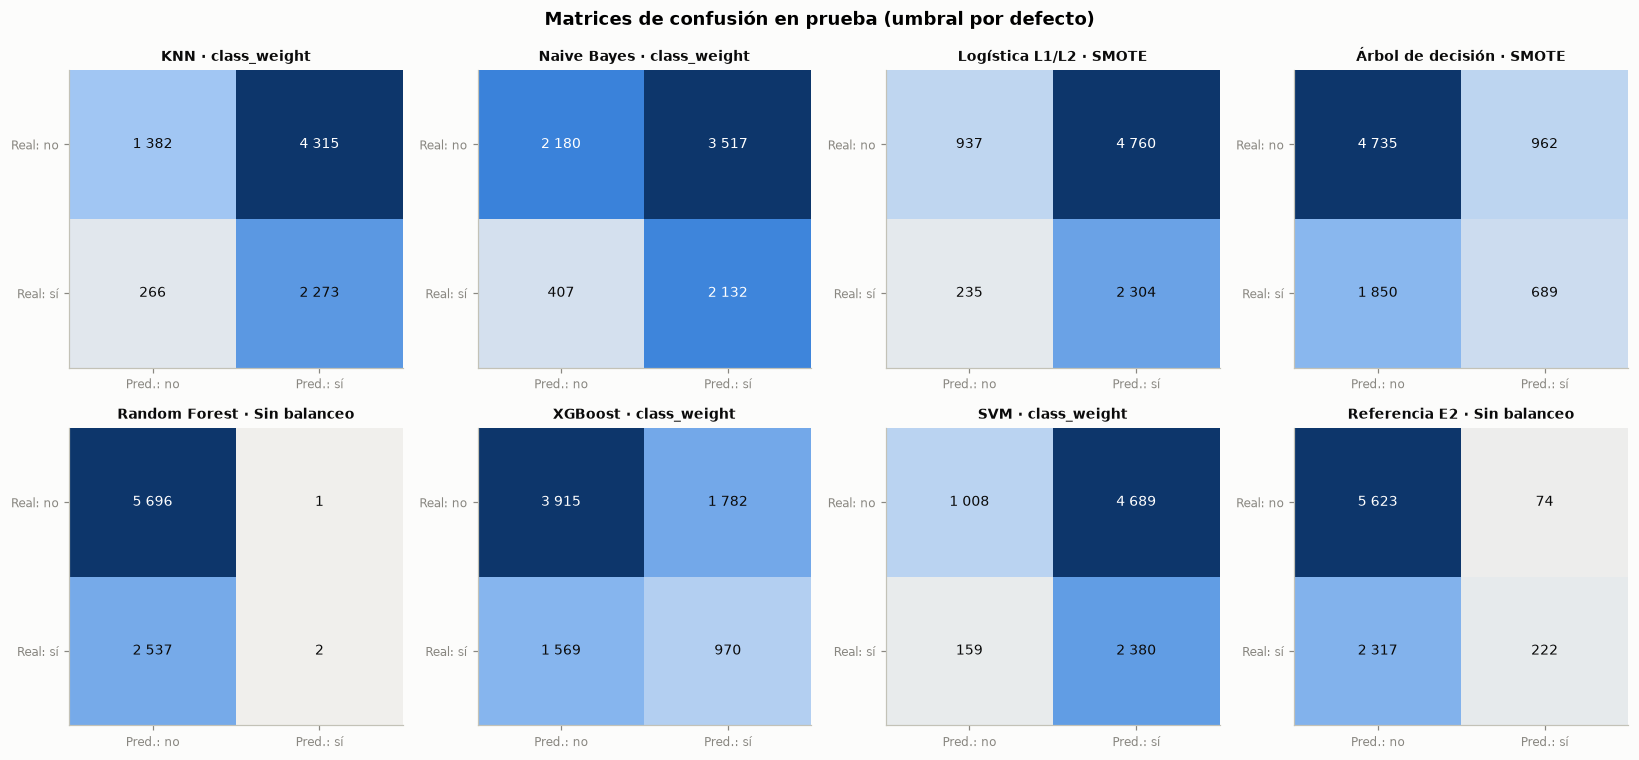

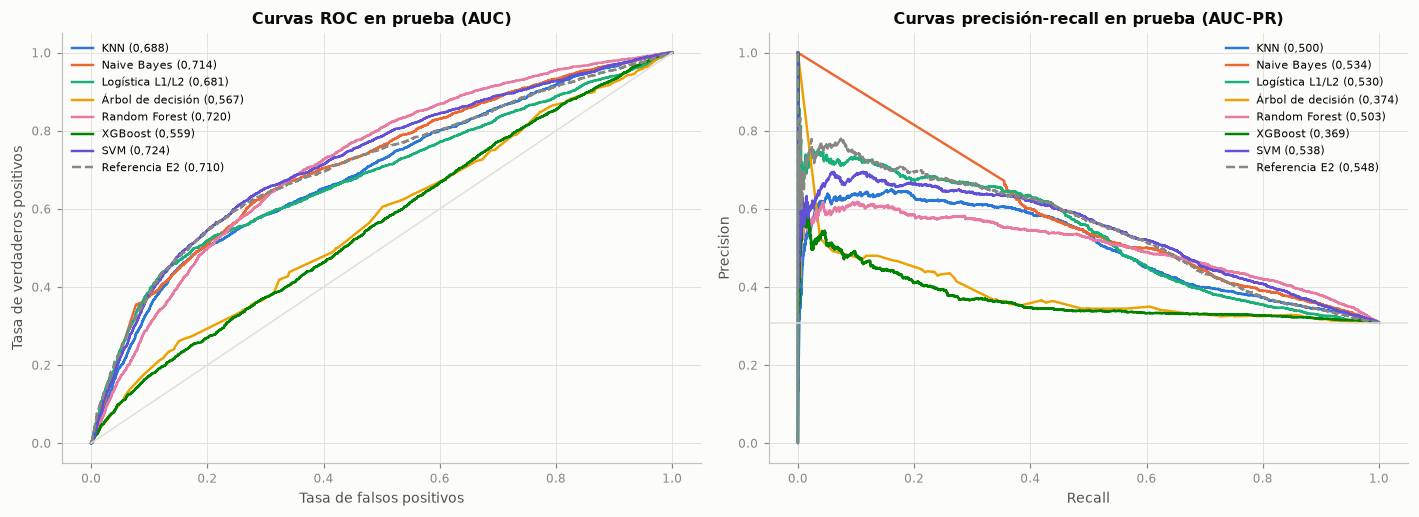

**Interpretación.** En prueba, el mayor AUC-PR es el de SVM (class_weight, Grid Search): 0,538 [0,516; 0,560], con AUC de 0,724 [0,711; 0,736]. La referencia del Entregable 2 obtiene un AUC-PR de 0,548 [0,526; 0,568] y un AUC de 0,710. El recall con el umbral por defecto va de 0,001 a 0,937, y la tasa de suscripción en prueba es del 30,8 %.

Lo anterior indica que el modelo base del Entregable 2, una logística con regularización fuerte y sin balanceo, iguala o supera a los finalistas optimizados en AUC-PR: con un cambio de régimen entre el entrenamiento y la prueba, la simplicidad y la regularización generalizan mejor que la flexibilidad. Hay que tener en cuenta que la prueba tiene una prevalencia casi cinco veces mayor que el entrenamiento: un AUC-PR aleatorio sería igual a esa prevalencia, de modo que las cifras de prueba no son comparables con las del bucle externo, donde la prevalencia era menor. El umbral por defecto, fijado con la tasa del entrenamiento, deja sin marcar a la mayoría de los suscriptores en los modelos sin balanceo; los modelos balanceados recuperan recall a costa de precisión. Los intervalos de confianza del AUC-PR de los dos mejores modelos se solapan, así que el orden entre ellos debe confirmarse con la prueba de DeLong (sección 8.2).

Por ello, se recomienda usar el ordenamiento (AUC y AUC-PR) para decidir a quién llamar primero, que es el uso del modelo, y fijar el punto de operación con probabilidades recalibradas al régimen vigente (sección 7.4) en lugar del umbral por defecto.

In [63]:
from sklearn.metrics import average_precision_score, roc_auc_score, roc_curve

fin_clf = {k: v for k, v in finales.items() if v["tarea"] == "clf"}
orden_fin = [f"clf_{m_}" for m_ in cfg.MODELOS_CLF if f"clf_{m_}" in fin_clf] + ["clf_referencia_e2"]
yte = y_te.to_numpy()
filas = []
for k in orden_fin:
    f_ = fin_clf[k]
    s_ = f_["puntaje_te"]
    ic_auc = st.ic_bootstrap(roc_auc_score, yte, s_, n_rep=1000)
    ic_ap = st.ic_bootstrap(average_precision_score, yte, s_, n_rep=1000)
    filas.append({"Modelo": "Referencia E2 (logística C = 0,01)" if k.endswith("e2") else NM[f_["modelo"]],
                  "Balanceo": NB[f_["balanceo"]], "Optimizador": NO.get(f_["optimizador"], "—"),
                  "Accuracy": f_["accuracy"], "Precision": f_["precision"], "Recall": f_["recall"], "F1": f_["f1"],
                  "AUC": f_["auc"], "AUC IC 95 %": f"[{num(ic_auc[0], 3)}; {num(ic_auc[1], 3)}]",
                  "AUC-PR": f_["auc_pr"], "AUC-PR IC 95 %": f"[{num(ic_ap[0], 3)}; {num(ic_ap[1], 3)}]",
                  "ic_auc": ic_auc, "ic_ap": ic_ap, "clave": k})
res_te = pd.DataFrame(filas)
tabla(res_te.drop(columns=["ic_auc", "ic_ap", "clave"]), dec=3, indice=False)

fig, axs = plt.subplots(2, 4, figsize=(15, 7))
for ax, k in zip(axs.ravel(), orden_fin):
    f_ = fin_clf[k]
    cm = confusion_matrix(yte, f_["pred_te"].astype(int))
    mapa_calor(ax, cm, ["Real: no", "Real: sí"], ["Pred.: no", "Pred.: sí"], CMAP_SEQ, 0, cm.max(), dec=0, tam=9)
    ax.set_title(("Referencia E2" if k.endswith("e2") else NM[f_["modelo"]]) + f" · {NB[f_['balanceo']]}", fontsize=9)
    plt.setp(ax.get_xticklabels(), rotation=0, ha="center")
fig.suptitle("Matrices de confusión en prueba (umbral por defecto)")
plt.tight_layout()
plt.show()

fig, axs = plt.subplots(1, 2, figsize=(13, 4.8))
for k in orden_fin:
    f_ = fin_clf[k]
    col = GRIS if k.endswith("e2") else COLOR_MODELO[f_["modelo"]]
    nombre = "Referencia E2" if k.endswith("e2") else NM[f_["modelo"]]
    fpr, tpr, _ = roc_curve(yte, f_["puntaje_te"])
    axs[0].plot(fpr, tpr, color=col, lw=1.6, ls="--" if k.endswith("e2") else "-", label=f"{nombre} ({num(f_['auc'], 3)})")
    pr_, rc_, _ = curva_pr(yte, f_["puntaje_te"])
    axs[1].plot(rc_, pr_, color=col, lw=1.6, ls="--" if k.endswith("e2") else "-", label=f"{nombre} ({num(f_['auc_pr'], 3)})")
axs[0].plot([0, 1], [0, 1], color=REJILLA, lw=1)
axs[1].axhline(yte.mean(), color=REJILLA, lw=1)
axs[0].set(title="Curvas ROC en prueba (AUC)", xlabel="Tasa de falsos positivos", ylabel="Tasa de verdaderos positivos")
axs[1].set(title="Curvas precisión-recall en prueba (AUC-PR)", xlabel="Recall", ylabel="Precision")
for ax in axs:
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

mod_ = res_te[~res_te["clave"].str.endswith("e2")]
mejor_te = mod_.loc[mod_["AUC-PR"].idxmax()]
refe = res_te[res_te["clave"].str.endswith("e2")].iloc[0]
interpretar(
    f"En prueba, el mayor AUC-PR es el de {mejor_te['Modelo']} ({mejor_te['Balanceo']}, {mejor_te['Optimizador']}): "
    f"{num(mejor_te['AUC-PR'], 3)} {mejor_te['AUC-PR IC 95 %']}, con AUC de {num(mejor_te['AUC'], 3)} "
    f"{mejor_te['AUC IC 95 %']}. La referencia del Entregable 2 obtiene un AUC-PR de {num(refe['AUC-PR'], 3)} "
    f"{refe['AUC-PR IC 95 %']} y un AUC de {num(refe['AUC'], 3)}. El recall con el umbral por defecto va de "
    f"{num(res_te['Recall'].min(), 3)} a {num(res_te['Recall'].max(), 3)}, y la tasa de suscripción en prueba es del "
    f"{pct(yte.mean())}.",
    (("Lo anterior indica que el modelo base del Entregable 2, una logística con regularización fuerte y sin "
      "balanceo, iguala o supera a los finalistas optimizados en AUC-PR: con un cambio de régimen entre el "
      "entrenamiento y la prueba, la simplicidad y la regularización generalizan mejor que la flexibilidad. "
      if refe["AUC-PR"] >= mejor_te["AUC-PR"] else "") +
     conectar("Hay que tener en cuenta que", "La prueba tiene una prevalencia casi cinco veces mayor que el entrenamiento: "
             "un AUC-PR aleatorio sería igual a esa prevalencia, de modo que las cifras de prueba no son comparables con "
             "las del bucle externo, donde la prevalencia era menor. El umbral por defecto, fijado con la tasa del "
             "entrenamiento, deja sin marcar a la mayoría de los suscriptores en los modelos sin balanceo; los modelos "
             "balanceados recuperan recall a costa de precisión."
             + (" Los intervalos de confianza del AUC-PR de los dos mejores modelos se solapan, así que el orden entre "
                "ellos debe confirmarse con la prueba de DeLong (sección 8.2)."
                if (lambda d: d["ic_ap"].iloc[0][0] <= d["ic_ap"].iloc[1][1])(res_te.sort_values("AUC-PR", ascending=False))
                else " Los intervalos de confianza del AUC-PR de los dos mejores modelos no se solapan."))),
    conectar("Por ello, se recomienda", "Usar el ordenamiento (AUC y AUC-PR) para decidir a quién llamar primero, que es "
             "el uso del modelo, y fijar el punto de operación con probabilidades recalibradas al régimen vigente "
             "(sección 7.4) en lugar del umbral por defecto."))

exportar("finalistas_prueba", res_te.drop(columns=["ic_auc", "ic_ap"]).assign(
    auc_inf=[v[0] for v in res_te["ic_auc"]], auc_sup=[v[1] for v in res_te["ic_auc"]],
    ap_inf=[v[0] for v in res_te["ic_ap"]], ap_sup=[v[1] for v in res_te["ic_ap"]]))
filas_c = []
for k in orden_fin:
    f_ = fin_clf[k]
    nombre = "Referencia E2" if k.endswith("e2") else NM[f_["modelo"]]
    fpr, tpr, _ = roc_curve(yte, f_["puntaje_te"])
    sel = np.unique(np.linspace(0, len(fpr) - 1, 250).astype(int))
    filas_c += [{"modelo": nombre, "curva": "ROC", "x": a, "y": b} for a, b in zip(fpr[sel], tpr[sel])]
    pr_, rc_, _ = curva_pr(yte, f_["puntaje_te"])
    sel = np.unique(np.linspace(0, len(pr_) - 1, 250).astype(int))
    filas_c += [{"modelo": nombre, "curva": "PR", "x": a, "y": b} for a, b in zip(rc_[sel], pr_[sel])]
    cm = confusion_matrix(yte, f_["pred_te"].astype(int))
    filas_c += [{"modelo": nombre, "curva": "CM", "x": i, "y": j, "valor": int(cm[i, j])} for i in range(2) for j in range(2)]
exportar("curvas_prueba", pd.DataFrame(filas_c))


## 7.4 Calibración de probabilidades

Para cada finalista con probabilidades se evalúa la calibración en prueba con el diagrama de confiabilidad (10 *bins* de igual ancho), el Brier y el error de calibración esperado (ECE). Se comparan tres recalibraciones, ajustadas sin usar la prueba:

- **Platt** (sigmoide) e **isotónica**: el modelo se reajusta con el primer 80 % del entrenamiento y el calibrador con el 20 % final, de modo que ve probabilidades fuera de muestra. Para la SVM, Platt es además la forma de obtener probabilidades a partir de su función de decisión.
- **Mensual del intercepto** (método del Entregable 2, generalizado): cada mes se desplaza el logit para que la probabilidad media iguale la tasa observada del mes anterior, ya cerrado. Corrige el cambio de prevalencia (*prior shift*; Saerens et al., 2002), que Platt y la isotónica no pueden anticipar porque se ajustan con datos de entrenamiento.

Modelo,Balanceo,Variante,Brier,ECE,Prob. media,AUC-PR,"F1 (umbral 0,5)"
KNN,class_weight,Sin recalibrar,"0,2990","0,3232","0,6283","0,4998","0,4981"
KNN,class_weight,Platt,"0,2506","0,1939","0,1144","0,3255","0,0000"
KNN,class_weight,Isotónica,"0,2497","0,1942","0,1143","0,3382","0,0000"
KNN,class_weight,Mensual (intercepto),"0,1764","0,0382","0,2834","0,5770","0,4883"
Naive Bayes,class_weight,Sin recalibrar,"0,4049","0,4109","0,7166","0,5343","0,5208"
Naive Bayes,class_weight,Platt,"0,2470","0,2199","0,0883","0,4644","0,0000"
Naive Bayes,class_weight,Isotónica,"0,2263","0,1885","0,1198","0,4356","0,0000"
Naive Bayes,class_weight,Mensual (intercepto),"0,2664","0,2356","0,3446","0,4777","0,5204"
Logística L1/L2,SMOTE,Sin recalibrar,"0,3050","0,3349","0,6432","0,5297","0,4799"
Logística L1/L2,SMOTE,Platt,"0,2459","0,1876","0,1277","0,3681","0,0807"


Tasa real de suscripción en prueba: 0,3083


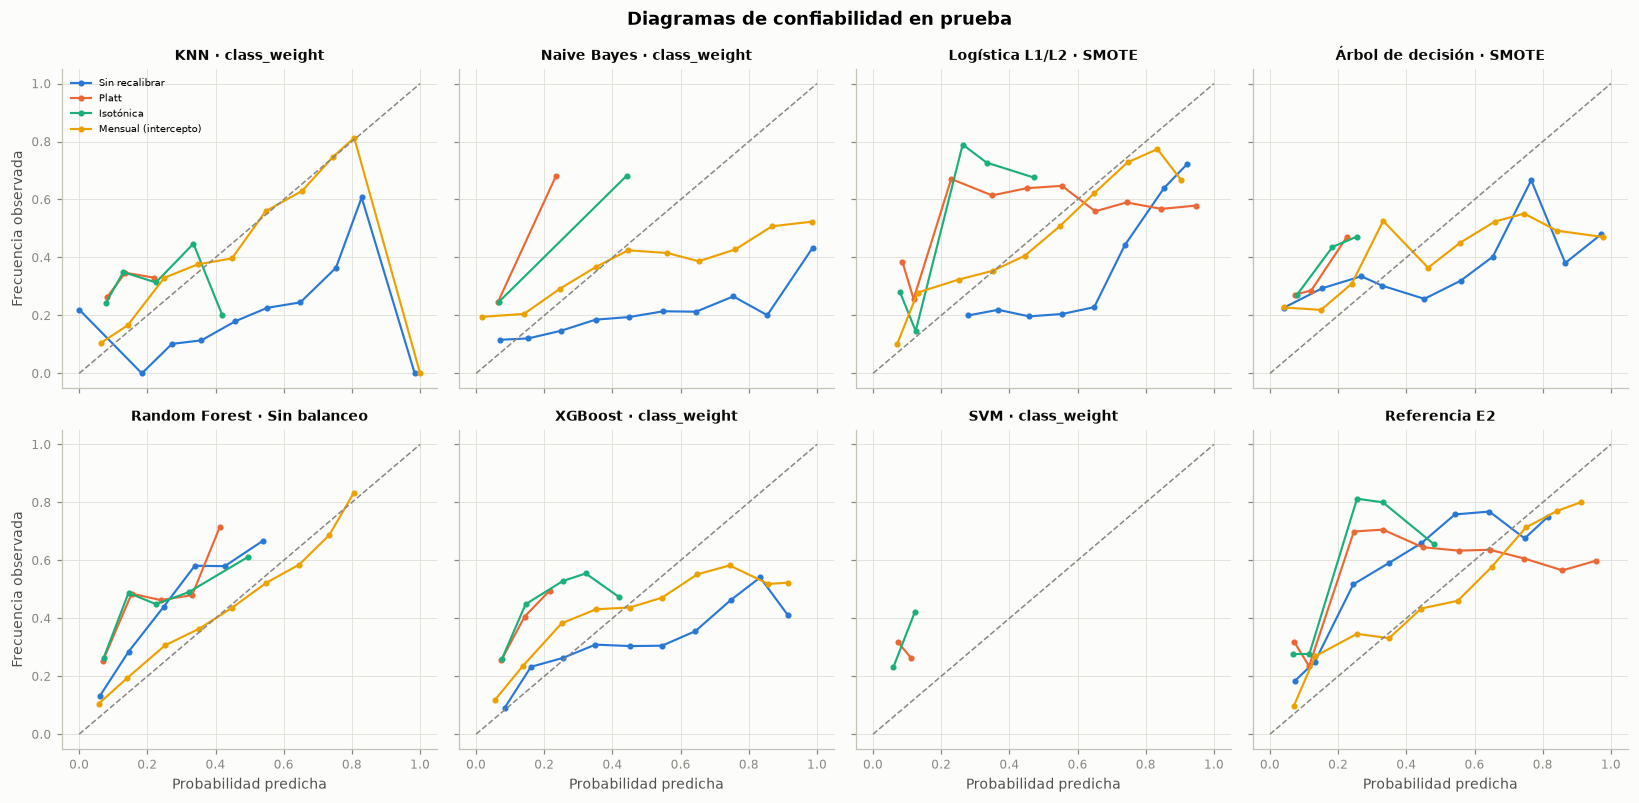

**Interpretación.** Sin recalibrar, el ECE en prueba va de 0,136 a 0,411 y la probabilidad media de 0,167 a 0,717, frente a una tasa real de 0,308. La mediana del ECE por variante es de 0,055 (Mensual (intercepto)), 0,189 (Sin recalibrar), 0,201 (Isotónica) y 0,204 (Platt).

Esto significa que la descalibración en prueba está dominada por el cambio de prevalencia: los modelos sin balanceo subestiman la probabilidad porque aprendieron con una tasa del 6 %, y los balanceados la distorsionan en la dirección contraria dentro del entrenamiento. Platt y la isotónica corrigen la forma de la curva con la tasa del final del entrenamiento, pero no pueden anticipar el régimen nuevo; la recalibración mensual sí lo sigue porque usa la tasa del mes que acaba de cerrar.

Por tal motivo, se opta por la variante con menor ECE mediano (Mensual (intercepto)) para cualquier uso que dependa del valor de la probabilidad (por ejemplo, estimar cuántas suscripciones dará una campaña), y documentar que exige observar las etiquetas de cada mes cerrado antes de predecir el siguiente.

In [64]:
with open(RES / "finales" / "recalibracion.pkl", "rb") as f:
    recal = pickle.load(f)
ult_mes = periodo_tr.iloc[-1]
m_ult = (periodo_tr == ult_mes).to_numpy()
filas, variantes_graf = [], {}
for k in orden_fin:
    f_, rc = fin_clf[k], recal[k]
    var = {"Sin recalibrar": f_["puntaje_te"] if f_["es_proba"] else None, "Platt": rc["platt"],
           "Isotónica": rc["isotonica"]}
    if f_["es_proba"]:
        var["Mensual (intercepto)"] = evm.recalibracion_mensual(f_["puntaje_te"], yte, periodo_te.to_numpy(),
                                                                f_["puntaje_tr"][m_ult], y_tr.to_numpy()[m_ult])
    variantes_graf[k] = var
    for v_, p_ in var.items():
        if p_ is None:
            continue
        filas.append({"Modelo": "Referencia E2" if k.endswith("e2") else NM[f_["modelo"]], "Balanceo": NB[f_["balanceo"]],
                      "Variante": v_, "Brier": brier_score_loss(yte, p_), "ECE": evm.ece(yte, p_),
                      "Prob. media": float(np.mean(p_)), "AUC-PR": average_precision_score(yte, p_),
                      "F1 (umbral 0,5)": f1_score(yte, p_ >= 0.5), "clave": k})
cal = pd.DataFrame(filas)
tabla(cal.drop(columns="clave"), dec=4, indice=False)
print(f"Tasa real de suscripción en prueba: {num(yte.mean(), 4)}")

fig, axs = plt.subplots(2, 4, figsize=(15, 7.4), sharex=True, sharey=True)
for ax, k in zip(axs.ravel(), orden_fin):
    for i, (v_, p_) in enumerate(variantes_graf[k].items()):
        if p_ is None:
            continue
        cc = evm.curva_confiabilidad(yte, p_)
        ax.plot(cc["prob_media"], cc["frecuencia"], marker="o", ms=3, lw=1.4, color=CAT[i], label=v_)
    ax.plot([0, 1], [0, 1], color=GRIS, ls="--", lw=1)
    ax.set_title("Referencia E2" if k.endswith("e2") else f"{NM[fin_clf[k]['modelo']]} · {NB[fin_clf[k]['balanceo']]}",
                 fontsize=9)
axs[0, 0].legend(fontsize=6.5)
for ax in axs[-1]:
    ax.set_xlabel("Probabilidad predicha")
for ax in axs[:, 0]:
    ax.set_ylabel("Frecuencia observada")
fig.suptitle("Diagramas de confiabilidad en prueba")
plt.tight_layout()
plt.show()

mejor_var = cal.groupby("Variante")["ECE"].median().sort_values()
sr = cal[cal["Variante"] == "Sin recalibrar"]
interpretar(
    f"Sin recalibrar, el ECE en prueba va de {num(sr['ECE'].min(), 3)} a {num(sr['ECE'].max(), 3)} y la probabilidad "
    f"media de {num(sr['Prob. media'].min(), 3)} a {num(sr['Prob. media'].max(), 3)}, frente a una tasa real de "
    f"{num(yte.mean(), 3)}. La mediana del ECE por variante es de "
    f"{enumerar([num(v, 3) + ' (' + k + ')' for k, v in mejor_var.items()], codigo=False)}.",
    conectar("Esto significa que", "La descalibración en prueba está dominada por el cambio de prevalencia: los modelos "
             "sin balanceo subestiman la probabilidad porque aprendieron con una tasa del 6 %, y los balanceados la "
             "distorsionan en la dirección contraria dentro del entrenamiento. Platt y la isotónica corrigen la forma "
             "de la curva con la tasa del final del entrenamiento, pero no pueden anticipar el régimen nuevo; la "
             "recalibración mensual sí lo sigue porque usa la tasa del mes que acaba de cerrar."),
    conectar(f"Por tal motivo, se opta por", f"La variante con menor ECE mediano ({mejor_var.index[0]}) para cualquier uso "
             "que dependa del valor de la probabilidad (por ejemplo, estimar cuántas suscripciones dará una campaña), "
             "y documentar que exige observar las etiquetas de cada mes cerrado antes de predecir el siguiente."))

exportar("calibracion", cal)
exportar("calibracion_curvas", pd.DataFrame([{"modelo": "Referencia E2" if k.endswith("e2") else NM[fin_clf[k]["modelo"]],
    "variante": v_, **r_} for k in orden_fin for v_, p_ in variantes_graf[k].items() if p_ is not None
    for r_ in evm.curva_confiabilidad(yte, p_).to_dict("records")]))


## 7.5 Regresión: duración de la llamada

Los finalistas de regresión se evalúan en prueba con RMSE y MAE en escala `log1p(duration)` y en segundos, frente al pronóstico de la media del entrenamiento. Para cada uno se reportan las pruebas de White (homocedasticidad, versión especial con ŷ y ŷ²) y BDS (independencia, dimensión 2, sobre los últimos 2 000 residuos en orden temporal).

Modelo,Optimizador,RMSE (log),MAE (log),RMSE (s),MAE (s),R²,p White,p BDS (m = 2)
KNN,Genético (DEAP),"0,9342","0,6955","258,8261","155,4867","0,0427","< 0,001","< 0,001"
Ridge,Random Search,"0,9375","0,6927","256,3659","154,8141","0,0360","< 0,001","< 0,001"
Lasso,Genético (DEAP),"0,9459","0,7089","266,6585","157,9900","0,0186","< 0,001","< 0,001"
Árbol de decisión,Grid Search,"0,9166","0,6925","258,0030","155,2728","0,0784","< 0,001","< 0,001"
Random Forest,Random Search,"0,9120","0,6896","261,7158","154,7025","0,0877","< 0,001","< 0,001"
XGBoost,Bayesiana (Optuna TPE),"0,9298","0,6973","263,0896","156,0172","0,0518","< 0,001","< 0,001"
SVR,Genético (DEAP),"0,9639","0,7081","253,9521","159,2287","-0,0190","< 0,001","< 0,001"
Media del entrenamiento (referencia),—,"0,9563","0,7154","268,1270","159,1151","-0,0030",—,—


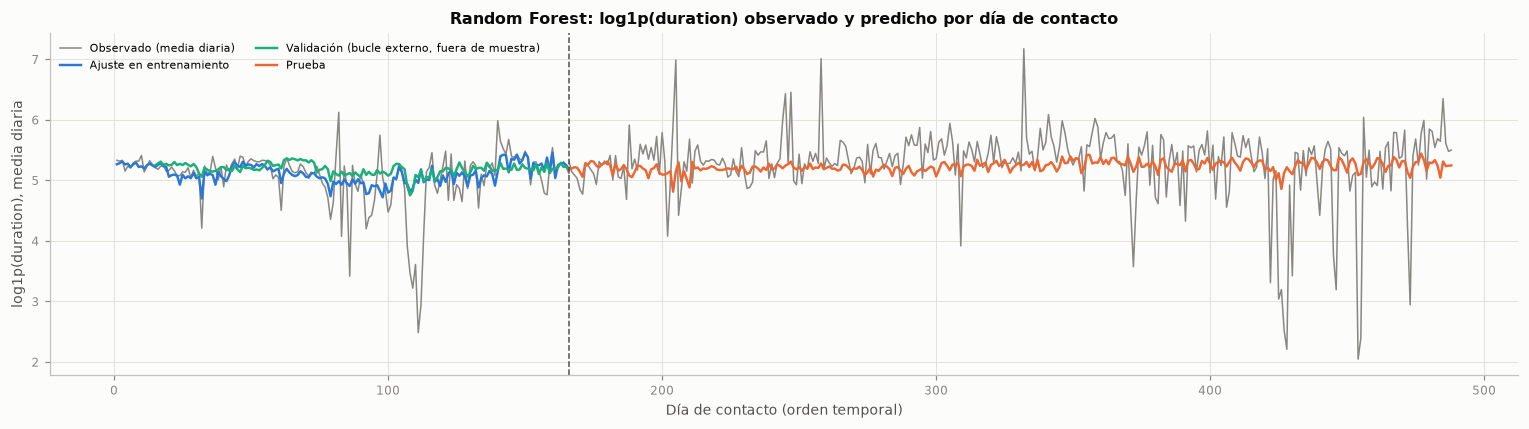

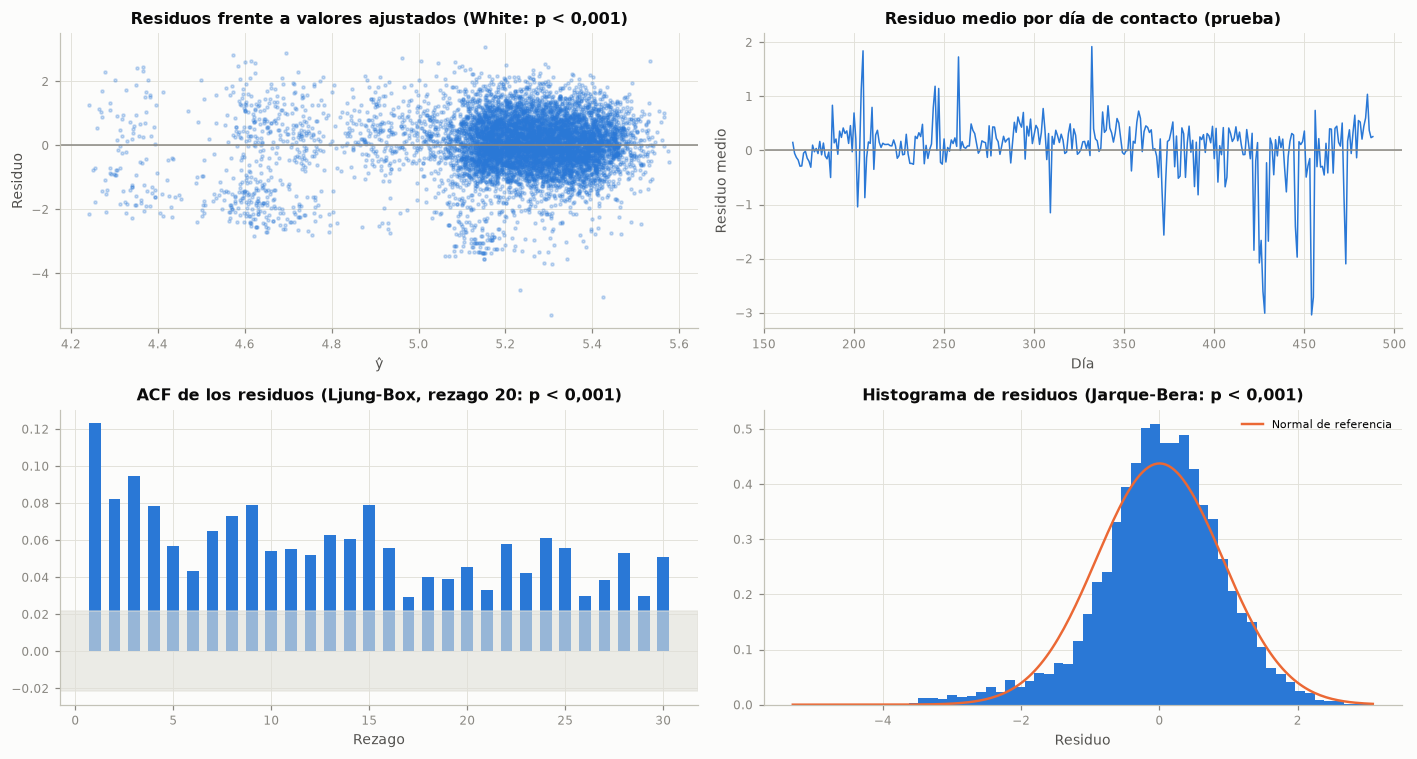

**Interpretación.** El mejor finalista de regresión es Random Forest, con un RMSE de 0,9120 en escala log (262 s) y un R² de 0,088; la media del entrenamiento logra un RMSE de 0,9563 y un R² de -0,003. En sus residuos, White da p < 0,001, BDS p < 0,001, Ljung-Box en el rezago 20 p < 0,001 y Jarque-Bera p < 0,001 (asimetría -0,60, curtosis en exceso 1,40).

Esto quiere decir que con información previa a la llamada el mejor modelo explica apenas el 9 % de la varianza de la duración: el RMSE baja un 4,6 % frente a la media del entrenamiento. Las predicciones siguen el nivel medio por día, pero no anticipan qué llamadas serán muy cortas o muy largas. Los residuos heredan entonces la estructura de la propia duración: colas pesadas (no normalidad), varianza que cambia con el nivel y dependencia serial entre llamadas cercanas en el tiempo, que el modelo no captura porque no usa información temporal.

En consecuencia, se decide reportar la rama de regresión como un resultado de señal débil: útil, a lo sumo, para estimar la carga media de un día, pero no para planificar llamadas individuales, porque la duración depende sobre todo de lo que ocurre durante la llamada. La sección 8.3 verifica con el Model Confidence Set si la mejora frente a la media es estadísticamente distinguible.

In [65]:
fin_reg = {k: v for k, v in finales.items() if v["tarea"] == "reg"}
orden_reg = [f"reg_{m_}" for m_ in cfg.MODELOS_REG if f"reg_{m_}" in fin_reg]
rte, rtr = part.r_te.to_numpy(), part.r_tr.to_numpy()
media_tr = rtr.mean()
filas, diag = [], {}
for k in orden_reg + ["media"]:
    pred = fin_reg[k]["pred_te"] if k != "media" else np.full_like(rte, media_tr)
    d_ = evm.diagnostico_residuos(rte, pred) if k != "media" else None
    diag[k] = d_
    filas.append({"Modelo": NM[fin_reg[k]["modelo"]] if k != "media" else "Media del entrenamiento (referencia)",
                  "Optimizador": NO[fin_reg[k]["optimizador"]] if k != "media" else "—",
                  "RMSE (log)": root_mean_squared_error(rte, pred), "MAE (log)": mean_absolute_error(rte, pred),
                  "RMSE (s)": root_mean_squared_error(np.expm1(rte), np.expm1(pred)),
                  "MAE (s)": mean_absolute_error(np.expm1(rte), np.expm1(pred)), "R²": r2_score(rte, pred),
                  "p White": d_["p_white"] if d_ else np.nan, "p BDS (m = 2)": d_["p_bds"][0] if d_ else np.nan,
                  "clave": k})
res_reg = pd.DataFrame(filas)
tabla(res_reg.drop(columns="clave").assign(**{"p White": res_reg["p White"].map(lambda v: pval(v) if np.isfinite(v) else "—"),
                                              "p BDS (m = 2)": res_reg["p BDS (m = 2)"].map(lambda v: pval(v) if np.isfinite(v) else "—")}),
      dec=4, indice=False)

mejor_r = res_reg[res_reg["clave"] != "media"].sort_values("RMSE (log)").iloc[0]
kr = mejor_r["clave"]
fr_ = fin_reg[kr]
oof_r = oof[(oof["tarea"] == "reg") & (oof["modelo"] == fr_["modelo"]) & (oof["optimizador"] == fr_["optimizador"])]
dia_media = lambda idx, v: pd.Series(v, index=idx).groupby(tiempo.loc[idx, "dia"].to_numpy()).mean()
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(dia_media(X_tr.index, rtr), color=GRIS, lw=1, label="Observado (media diaria)")
ax.plot(dia_media(X_te.index, rte), color=GRIS, lw=1)
ax.plot(dia_media(X_tr.index, fr_["puntaje_tr"]), color=AZUL, lw=1.6, label="Ajuste en entrenamiento")
ax.plot(dia_media(pd.Index(oof_r["indice"]), oof_r["pred"].to_numpy()), color=AGUAMARINA, lw=1.6,
        label="Validación (bucle externo, fuera de muestra)")
ax.plot(dia_media(X_te.index, fr_["pred_te"]), color=NARANJA, lw=1.6, label="Prueba")
ax.axvline(tiempo.loc[X_te.index[0], "dia"], color=TINTA_2, ls="--", lw=1)
ax.set(title=f"{NM[fr_['modelo']]}: log1p(duration) observado y predicho por día de contacto",
       xlabel="Día de contacto (orden temporal)", ylabel="log1p(duration), media diaria")
ax.legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.show()

d_ = diag[kr]
e_ = rte - fr_["pred_te"]
fig, axs = plt.subplots(2, 2, figsize=(13, 7))
axs[0, 0].scatter(fr_["pred_te"], e_, s=4, alpha=0.25, color=AZUL)
axs[0, 0].axhline(0, color=GRIS, lw=1)
axs[0, 0].set(title=f"Residuos frente a valores ajustados (White: {p_txt(d_['p_white'])})", xlabel="ŷ", ylabel="Residuo")
axs[0, 1].plot(dia_media(X_te.index, e_), color=AZUL, lw=1)
axs[0, 1].axhline(0, color=GRIS, lw=1)
axs[0, 1].set(title="Residuo medio por día de contacto (prueba)", xlabel="Día", ylabel="Residuo medio")
acf_v = acf(e_, nlags=30)
axs[1, 0].bar(range(1, 31), acf_v[1:], color=AZUL, width=0.6)
lim = 1.96 / np.sqrt(len(e_))
axs[1, 0].axhspan(-lim, lim, color=REJILLA, alpha=0.6)
lb = pd.DataFrame(d_["ljung_box"])
axs[1, 0].set(title=f"ACF de los residuos (Ljung-Box, rezago 20: {p_txt(lb['lb_pvalue'].iloc[-1])})", xlabel="Rezago")
axs[1, 1].hist(e_, bins=60, color=AZUL, density=True)
xx = np.linspace(e_.min(), e_.max(), 200)
axs[1, 1].plot(xx, stats.norm.pdf(xx, e_.mean(), e_.std()), color=NARANJA, lw=1.6, label="Normal de referencia")
axs[1, 1].set(title=f"Histograma de residuos (Jarque-Bera: {p_txt(d_['p_jarque_bera'])})", xlabel="Residuo")
axs[1, 1].legend(fontsize=7)
plt.tight_layout()
plt.show()

ref_r = res_reg[res_reg["clave"] == "media"].iloc[0]
interpretar(
    f"El mejor finalista de regresión es {mejor_r['Modelo']}, con un RMSE de {num(mejor_r['RMSE (log)'], 4)} en escala log "
    f"({num(mejor_r['RMSE (s)'], 0)} s) y un R² de {num(mejor_r['R²'], 3)}; la media del entrenamiento logra un RMSE de "
    f"{num(ref_r['RMSE (log)'], 4)} y un R² de {num(ref_r['R²'], 3)}. En sus residuos, White da {p_txt(d_['p_white'])}, "
    f"BDS {p_txt(d_['p_bds'][0])}, Ljung-Box en el rezago 20 {p_txt(lb['lb_pvalue'].iloc[-1])} y Jarque-Bera "
    f"{p_txt(d_['p_jarque_bera'])} (asimetría {num(d_['asimetria'], 2)}, curtosis en exceso {num(d_['curtosis'], 2)}).",
    conectar("Esto quiere decir que", f"Con información previa a la llamada el mejor modelo explica apenas el "
             f"{pct(max(mejor_r['R²'], 0), 0)} de la varianza de la duración: el RMSE baja un "
             f"{pct(1 - mejor_r['RMSE (log)'] / ref_r['RMSE (log)'], 1)} frente a la media del entrenamiento. Las "
             "predicciones siguen el nivel medio por día, pero no anticipan qué llamadas serán muy cortas o muy largas. "
             "Los residuos heredan entonces la estructura de la propia duración: "
             "colas pesadas (no normalidad), varianza que cambia con el nivel y dependencia serial entre llamadas "
             "cercanas en el tiempo, que el modelo no captura porque no usa información temporal."),
    conectar("En consecuencia, se decide", "Reportar la rama de regresión como un resultado de señal débil: útil, a lo "
             "sumo, para estimar la carga media de un día, pero no para planificar llamadas individuales, porque la "
             "duración depende sobre todo de lo que ocurre durante la llamada. La sección 8.3 verifica con el Model "
             "Confidence Set si la mejora frente a la media es estadísticamente distinguible."))

exportar("regresion_prueba", res_reg)
serie = pd.concat([dia_media(X_tr.index, rtr).rename("observado").to_frame().assign(conjunto="entrenamiento"),
                   dia_media(X_te.index, rte).rename("observado").to_frame().assign(conjunto="prueba")])
serie["predicho"] = pd.concat([dia_media(X_tr.index, fr_["puntaje_tr"]), dia_media(X_te.index, fr_["pred_te"])]).values
serie["validacion"] = dia_media(pd.Index(oof_r["indice"]), oof_r["pred"].to_numpy()).reindex(serie.index).values
exportar("regresion_serie", serie.reset_index(names="dia"))
exportar("regresion_residuos", {"modelo": NM[fr_["modelo"]], "acf": acf_v[1:].tolist(), "lim": lim,
                                "hist": np.histogram(e_, bins=40)[0].tolist(),
                                "bordes": np.histogram(e_, bins=40)[1].tolist(), "p_white": d_["p_white"],
                                "p_bds": d_["p_bds"], "p_jb": d_["p_jarque_bera"],
                                "ljung_box": lb.to_dict("records")})


## 7.6 Interpretabilidad global y local: SHAP y LIME

Los valores de Shapley (Lundberg y Lee, 2017) reparten la diferencia entre la predicción de una observación y la predicción media entre las variables, cumpliendo eficiencia (las contribuciones suman esa diferencia), simetría y aditividad. Para los modelos de árboles se usa `TreeExplainer`, que los calcula de forma exacta y rápida (Lundberg et al., 2020); para los demás, un explicador por permutaciones. Las explicaciones se calculan sobre las columnas preprocesadas (después del *one-hot*), en la escala de salida del modelo (log-odds en XGBoost).

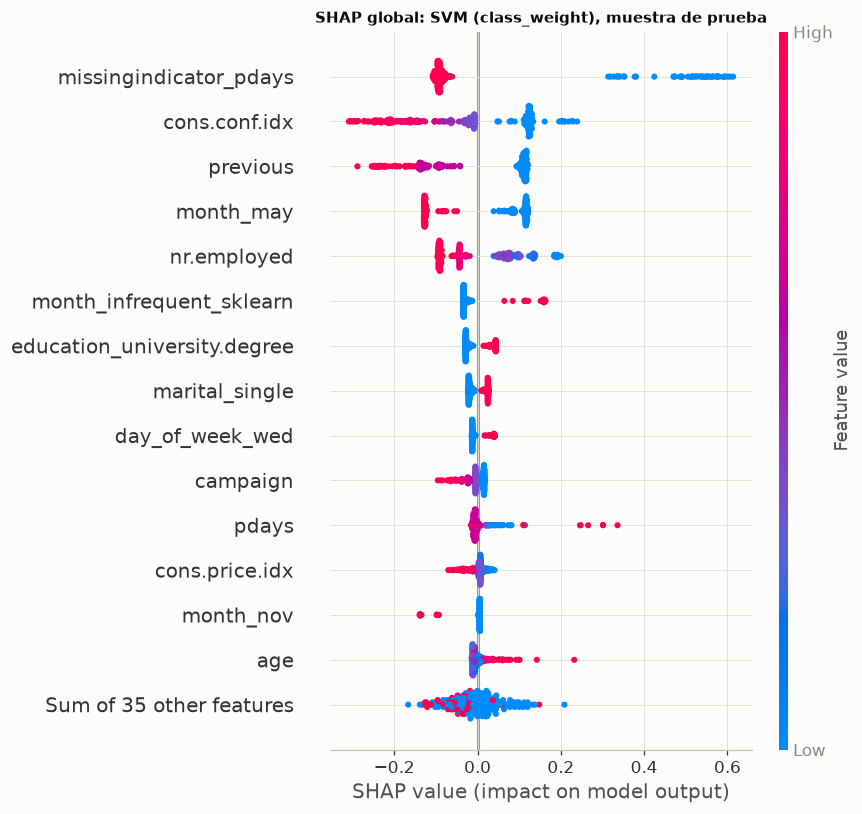

,Media |SHAP|
missingindicator_pdays,"0,1587"
cons.conf.idx,"0,1254"
previous,"0,1238"
month_may,"0,1139"
nr.employed,"0,0836"
month_infrequent_sklearn,"0,0496"
education_university.degree,"0,0308"
marital_single,"0,0204"
day_of_week_wed,"0,0170"
campaign,"0,0163"


In [66]:
from sklearn.tree import DecisionTreeClassifier

def explicar(f_, X, n=1000, seed=SEED):
    """Valores SHAP del modelo final sobre una muestra de X, en el espacio preprocesado."""
    pipe = f_["pipeline"]
    pre = pipe.named_steps["pre"]
    nombres = [n_.split("__", 1)[-1] for n_ in pre.get_feature_names_out()]
    Z = pd.DataFrame(pre.transform(X), columns=nombres, index=X.index)
    muestra = Z.sample(min(n, len(Z)), random_state=seed)
    mod = pipe.named_steps["modelo"]
    resto = [paso for nom, paso in pipe.steps if nom not in ("pre", "bal")]
    if f_["modelo"] in ("xgboost", "bosque", "arbol") and len(resto) == 1:
        exp = shap.TreeExplainer(mod)
        sv = exp(muestra)
        if sv.values.ndim == 3:
            sv = sv[:, :, 1]
    else:
        def f_salida(A):
            A = pd.DataFrame(A, columns=nombres).to_numpy()
            for paso in resto[:-1]:
                A = paso.transform(A)
            ult = resto[-1]
            if f_["tarea"] == "reg":
                return ult.predict(A)
            return ult.predict_proba(A)[:, 1] if hasattr(ult, "predict_proba") else ult.decision_function(A)
        fondo = shap.sample(Z, 100, random_state=seed)
        exp = shap.PermutationExplainer(f_salida, fondo)
        muestra = muestra.iloc[:300]
        sv = exp(muestra, silent=True)
    return sv, muestra, Z


mejor_clf_k = res_te.loc[res_te[~res_te["clave"].str.endswith("e2")]["AUC-PR"].idxmax(), "clave"]
f_best = fin_clf[mejor_clf_k]
sv_c, mu_c, Z_te = explicar(f_best, X_te)
plt.figure()
shap.plots.beeswarm(sv_c, max_display=15, show=False)
plt.title(f"SHAP global: {NM[f_best['modelo']]} ({NB[f_best['balanceo']]}), muestra de prueba", fontsize=10)
plt.tight_layout()
plt.show()

imp = pd.Series(np.abs(sv_c.values).mean(axis=0), index=mu_c.columns).sort_values(ascending=False)
tabla(imp.head(10).rename("Media |SHAP|").to_frame(), dec=4)

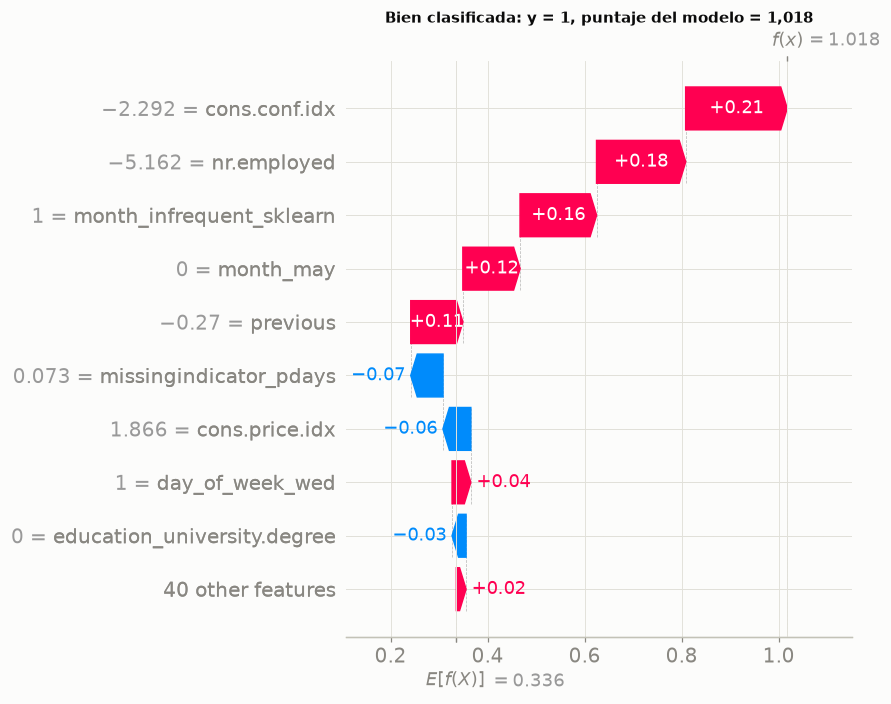

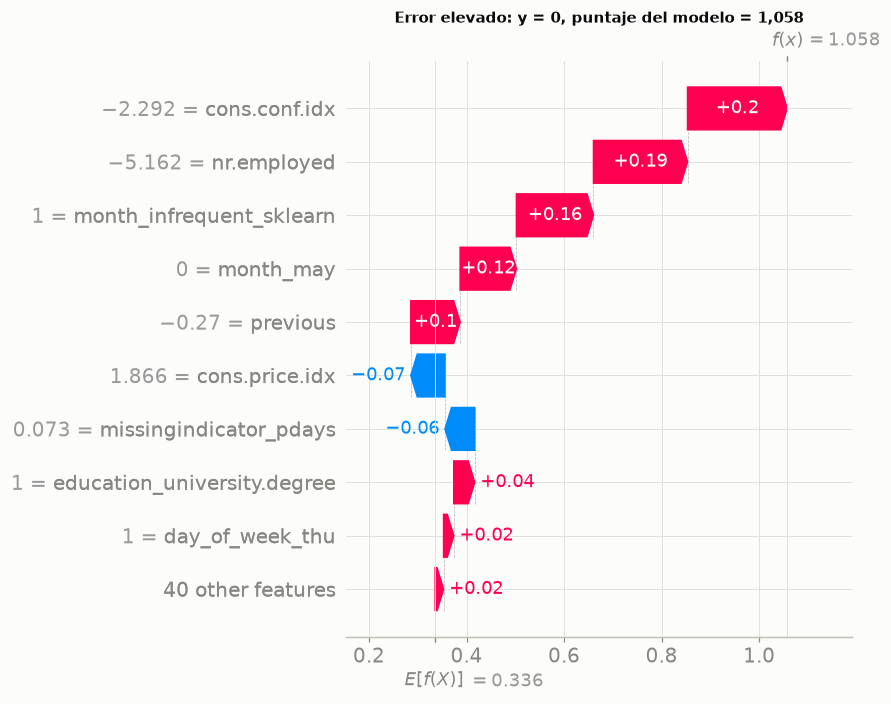

**Interpretación.** Globalmente, las variables con mayor contribución media son `missingindicator_pdays (0,159)`, `cons.conf.idx (0,125)`, `previous (0,124)` y `month_may (0,114)`. En la observación bien clasificada (y = 1), las que más empujan la predicción son `cons.conf.idx (0,21)`, `nr.employed (0,18)` y `month_infrequent_sklearn (0,16)`; en la de error elevado (y = 0, puntaje 1,058), `cons.conf.idx (0,20)`, `nr.employed (0,19)` y `month_infrequent_sklearn (0,16)`.

Lo anterior indica que el modelo se apoya sobre todo en el contexto macroeconómico y de calendario (que marca el régimen de la campaña) y en el historial de contactos previos; la observación con error elevado muestra el caso típico de falla: un cliente cuyo perfil y momento indican baja probabilidad, pero que no suscribe, lo que el modelo no puede anticipar con información previa a la llamada.

Por lo anterior, conviene leer las contribuciones como asociaciones aprendidas y no como efectos causales, y vigilar las variables de régimen: si el contexto macroeconómico cambia, su contribución también cambiará, lo que refuerza la recalibración mensual de la sección 7.4.

In [67]:
# Explicaciones locales: una observación bien clasificada y una con error elevado
s_m = f_best["puntaje_te"]
p_m = pd.Series(s_m, index=X_te.index).loc[mu_c.index]
y_m = y_te.loc[mu_c.index]
prob_m = expit(p_m) if not f_best["es_proba"] else p_m
error = (y_m - prob_m).abs()
i_bien = (prob_m.where(y_m == 1)).idxmax()           # suscriptor con la probabilidad más alta
i_mal = error.idxmax()                                 # mayor error absoluto
pos = {i: list(mu_c.index).index(i) for i in (i_bien, i_mal)}
for i, titulo in ((i_bien, "Bien clasificada"), (i_mal, "Error elevado")):
    plt.figure()
    shap.plots.waterfall(sv_c[pos[i]], max_display=10, show=False)
    plt.title(f"{titulo}: y = {int(y_m[i])}, puntaje del modelo = {num(float(p_m[i]), 3)}", fontsize=10)
    plt.tight_layout()
    plt.show()

top_bien = pd.Series(sv_c.values[pos[i_bien]], index=mu_c.columns).sort_values(key=np.abs, ascending=False).head(3)
top_mal = pd.Series(sv_c.values[pos[i_mal]], index=mu_c.columns).sort_values(key=np.abs, ascending=False).head(3)
interpretar(
    f"Globalmente, las variables con mayor contribución media son "
    f"{enumerar([f'{k} ({num(v, 3)})' for k, v in imp.head(4).items()])}. En la observación bien clasificada "
    f"(y = {int(y_m[i_bien])}), las que más empujan la predicción son "
    f"{enumerar([f'{k} ({num(v, 2)})' for k, v in top_bien.items()])}; en la de error elevado (y = {int(y_m[i_mal])}, "
    f"puntaje {num(float(p_m[i_mal]), 3)}), {enumerar([f'{k} ({num(v, 2)})' for k, v in top_mal.items()])}.",
    conectar("Lo anterior indica que", "El modelo se apoya sobre todo en el contexto macroeconómico y de calendario "
             "(que marca el régimen de la campaña) y en el historial de contactos previos; la observación con error "
             "elevado muestra el caso típico de falla: un cliente cuyo perfil y momento indican baja probabilidad, pero "
             "que " + ("suscribe" if int(y_m[i_mal]) == 1 else "no suscribe") + ", lo que el modelo no puede anticipar con "
             "información previa a la llamada."),
    conectar("Por lo anterior, conviene", "Leer las contribuciones como asociaciones aprendidas y no como efectos "
             "causales, y vigilar las variables de régimen: si el contexto macroeconómico cambia, su contribución "
             "también cambiará, lo que refuerza la recalibración mensual de la sección 7.4."))

exportar("shap_global", imp.head(15).rename("media_abs_shap").rename_axis("variable").reset_index().assign(modelo=NM[f_best["modelo"]]))
exportar("shap_local", pd.concat([pd.Series(sv_c.values[pos[i]], index=mu_c.columns).sort_values(key=np.abs, ascending=False)
                                  .head(10).rename("shap").rename_axis("variable").reset_index().assign(caso=t_, y=int(y_m[i]),
                                  puntaje=float(p_m[i]), base=float(np.ravel(sv_c.base_values)[pos[i]]))
                                  for i, t_ in ((i_bien, "Bien clasificada"), (i_mal, "Error elevado"))]))


### Comparación con LIME en XGBoost

LIME (Ribeiro et al., 2016) explica una predicción ajustando un modelo lineal ponderado sobre perturbaciones alrededor de la observación; SHAP reparte la predicción con valores de Shapley, que para árboles se calculan de forma exacta. Ambas son locales, pero difieren en tres aspectos: LIME depende del esquema de perturbación, del ancho del *kernel* y de la discretización, y puede cambiar entre corridas; sus pesos no suman la predicción (no cumple eficiencia), y explica un modelo sustituto local, mientras que SHAP explica el modelo original con una referencia global. Se espera que diverjan cuando la frontera es muy no lineal en la vecindad, cuando hay variables correlacionadas (LIME perturba cada una de forma independiente y crea combinaciones irreales) y con variables *one-hot*, cuya perturbación continua no tiene sentido. La comparación se hace sobre el finalista XGBoost y las mismas dos observaciones.

In [68]:
from lime.lime_tabular import LimeTabularExplainer

f_x = fin_clf["clf_xgboost"]
sv_x, mu_x, Z_te_x = explicar(f_x, pd.concat([X_te.loc[[i_bien, i_mal]],
                                              X_te.drop(index=[i_bien, i_mal]).sample(998, random_state=SEED)]))
pre_x = f_x["pipeline"].named_steps["pre"]
Z_tr_x = pd.DataFrame(pre_x.transform(X_tr), columns=mu_x.columns)
mod_x = f_x["pipeline"].named_steps["modelo"]
lime_exp = LimeTabularExplainer(Z_tr_x.sample(5000, random_state=SEED).to_numpy(), feature_names=list(mu_x.columns),
                                class_names=["no", "sí"], discretize_continuous=True, random_state=SEED)
filas = []
for i, nombre in ((i_bien, "Bien clasificada"), (i_mal, "Error elevado")):
    z = Z_te_x.loc[i].to_numpy()
    e_l = lime_exp.explain_instance(z, mod_x.predict_proba, num_features=10, num_samples=5000)
    pesos = {}
    for regla, w_ in e_l.as_list():
        var = next((c for c in sorted(mu_x.columns, key=len, reverse=True) if c in regla), regla)
        pesos[var] = pesos.get(var, 0) + w_
    sh = pd.Series(sv_x.values[list(mu_x.index).index(i)], index=mu_x.columns)
    top_sh = sh.abs().sort_values(ascending=False).head(10)
    comunes = set(top_sh.index) & set(pesos)
    rho = stats.spearmanr([abs(sh[c]) for c in comunes], [abs(pesos[c]) for c in comunes]).statistic if len(comunes) > 2 else np.nan
    signo = np.mean([np.sign(sh[c]) == np.sign(pesos[c]) for c in comunes]) if comunes else np.nan
    filas.append({"Observación": nombre, "Top 10 SHAP": ", ".join(top_sh.index[:5]) + "…",
                  "Top 10 LIME": ", ".join(list(pesos)[:5]) + "…", "Variables comunes en el top 10": len(comunes),
                  "Spearman de |importancia| (comunes)": rho, "% de signos coincidentes": 100 * signo,
                  "R² del modelo local de LIME": e_l.score})
cmp_lime = pd.DataFrame(filas)
tabla(cmp_lime, dec=3, indice=False)

gan = pd.Series(mod_x.get_booster().get_score(importance_type="gain"))
gan.index = [mu_x.columns[int(c[1:])] if c.startswith("f") and c[1:].isdigit() else c for c in gan.index]
imp_x = pd.DataFrame({"Media |SHAP|": pd.Series(np.abs(sv_x.values).mean(axis=0), index=mu_x.columns),
                      "Ganancia XGBoost": gan}).fillna(0)
imp_x = imp_x.sort_values("Media |SHAP|", ascending=False).head(10)
tabla(imp_x, dec=4)

interpretar(
    f"En las dos observaciones, SHAP y LIME comparten {enumerar([str(v) for v in cmp_lime['Variables comunes en el top 10']], codigo=False)} "
    f"de sus 10 variables principales, con una correlación de Spearman de "
    f"{enumerar([num(v, 2) if np.isfinite(v) else 'no calculable (menos de tres variables comunes)' for v in cmp_lime['Spearman de |importancia| (comunes)']], codigo=False)} entre las magnitudes y "
    f"{enumerar([num(v, 0) + ' %' for v in cmp_lime['% de signos coincidentes']], codigo=False)} de signos coincidentes; el "
    f"R² del modelo lineal local de LIME es {enumerar([num(v, 3) for v in cmp_lime['R² del modelo local de LIME']], codigo=False)}.",
    conectar("Esto significa que", ("Las dos técnicas coinciden en las variables dominantes pero no en el orden ni en "
             "la magnitud del resto:" if cmp_lime["Variables comunes en el top 10"].min() >= 5 else
             "Las dos técnicas coinciden solo de forma parcial, incluso en las variables principales:") + " LIME discretiza las variables continuas en cuartiles y perturba las columnas *one-hot* "
             "de forma independiente, y su ajuste lineal local explica solo una parte de la predicción (R² bajo), "
             "mientras que SHAP en árboles es exacto y aditivo. La ganancia de XGBoost, por su parte, mide cuánto "
             "reduce la pérdida cada variable al dividir y suele sobrevalorar variables con muchos valores posibles."),
    conectar("Por esta razón, lo indicado es", "Usar SHAP como explicación de referencia (global y local) y LIME solo "
             "como contraste: cuando discrepan, la diferencia suele venir de las perturbaciones irreales de LIME y no "
             "de un cambio real en el modelo."))

exportar("lime_shap", cmp_lime)
exportar("importancia_xgb", imp_x.reset_index(names="variable"))


Observación,Top 10 SHAP,Top 10 LIME,Variables comunes en el top 10,Spearman de |importancia| (comunes),% de signos coincidentes,R² del modelo local de LIME
Bien clasificada,"month_infrequent_sklearn, education_professional.course, job_technician, cons.conf.idx, day_of_week_thu…","month_infrequent_sklearn, education_infrequent_sklearn, default_unknown, cons.conf.idx, day_of_week_mon…",3,"1,000","66,667","0,222"
Error elevado,"month_infrequent_sklearn, cons.conf.idx, loan_yes, housing_yes, day_of_week_thu…","month_infrequent_sklearn, default_unknown, education_infrequent_sklearn, cons.conf.idx, pdays…",4,"1,000","75,000","0,208"


,Media |SHAP|,Ganancia XGBoost
cons.price.idx,"0,2651","50,5853"
month_infrequent_sklearn,"0,2170","121,5408"
cons.conf.idx,"0,1696","173,2239"
age,"0,1445","13,0426"
previous,"0,1297","11,5926"
missingindicator_pdays,"0,1129","25,5458"
contact_telephone,"0,1125","15,9307"
campaign,"0,0891","12,6048"
day_of_week_mon,"0,0681","15,3024"
month_may,"0,0592","61,6254"


**Interpretación.** En las dos observaciones, SHAP y LIME comparten 3 y 4 de sus 10 variables principales, con una correlación de Spearman de 1,00 y 1,00 entre las magnitudes y 67 % y 75 % de signos coincidentes; el R² del modelo lineal local de LIME es 0,222 y 0,208.

Esto significa que las dos técnicas coinciden solo de forma parcial, incluso en las variables principales: LIME discretiza las variables continuas en cuartiles y perturba las columnas *one-hot* de forma independiente, y su ajuste lineal local explica solo una parte de la predicción (R² bajo), mientras que SHAP en árboles es exacto y aditivo. La ganancia de XGBoost, por su parte, mide cuánto reduce la pérdida cada variable al dividir y suele sobrevalorar variables con muchos valores posibles.

Por esta razón, lo indicado es usar SHAP como explicación de referencia (global y local) y LIME solo como contraste: cuando discrepan, la diferencia suele venir de las perturbaciones irreales de LIME y no de un cambio real en el modelo.

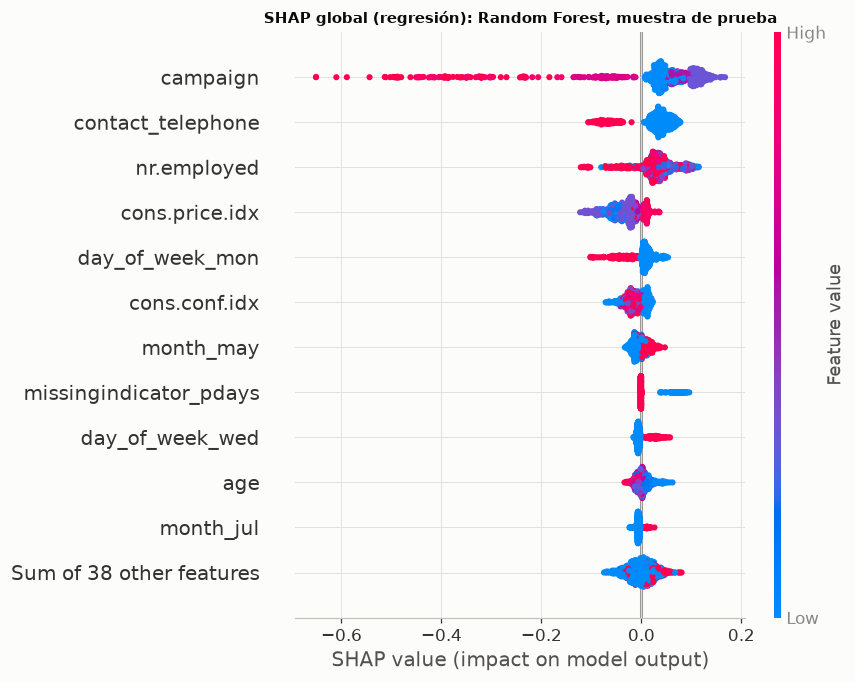

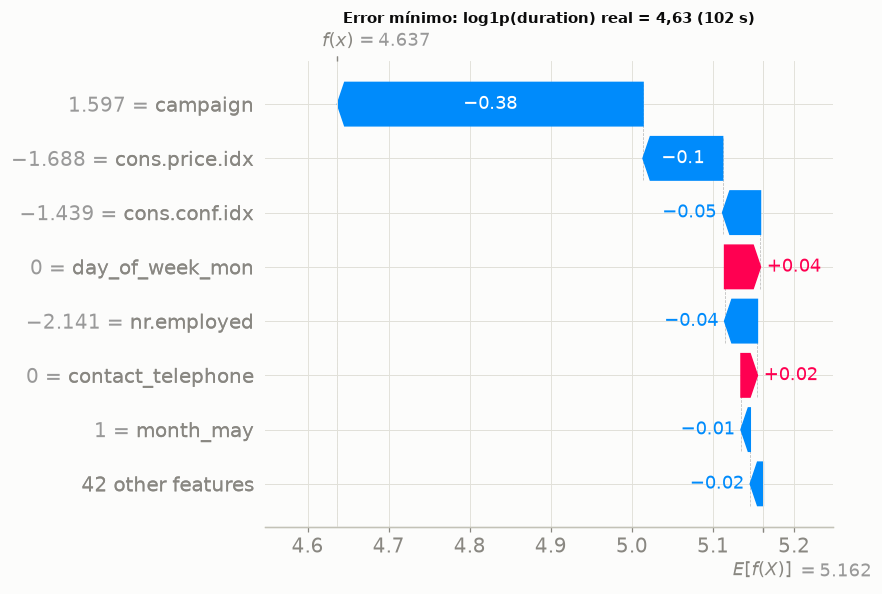

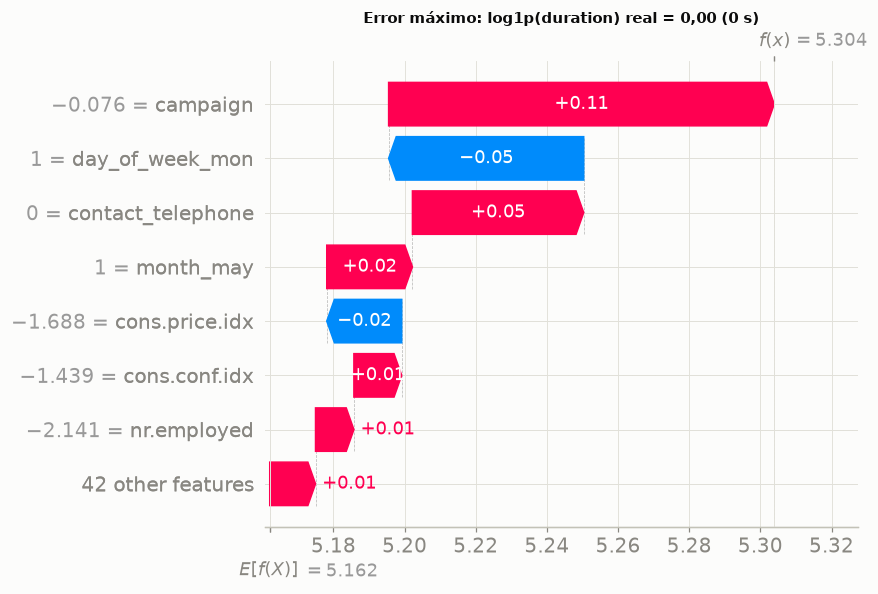

**Interpretación.** La desviación estándar de las predicciones del modelo de regresión en prueba es 0,21 en escala log, frente a 0,95 del objetivo; la contribución SHAP media más alta es la de `campaign`. La observación con mayor error es una llamada de 0 s.

Es decir, las predicciones varían mucho menos que la duración real: el modelo capta diferencias de nivel entre grupos de clientes y periodos, y los errores grandes corresponden a llamadas excepcionalmente cortas o largas que ninguna variable previa a la llamada anticipa.

Por tanto, corresponde mantener la conclusión de la sección 7.5: la explicación confirma que el problema de regresión carece de señal suficiente, no que el modelo esté mal especificado.

In [69]:
# SHAP del mejor modelo de regresión
sv_r, mu_r, _ = explicar(fr_, X_te)
fig = plt.figure(figsize=(9, 5))
shap.plots.beeswarm(sv_r, max_display=12, show=False)
plt.title(f"SHAP global (regresión): {NM[fr_['modelo']]}, muestra de prueba", fontsize=10)
plt.tight_layout()
plt.show()
err_r = pd.Series(np.abs(rte - fr_["pred_te"]), index=X_te.index).loc[mu_r.index]
i_rb, i_rm = err_r.idxmin(), err_r.idxmax()
for i, titulo in ((i_rb, "Error mínimo"), (i_rm, "Error máximo")):
    plt.figure()
    shap.plots.waterfall(sv_r[list(mu_r.index).index(i)], max_display=8, show=False)
    plt.title(f"{titulo}: log1p(duration) real = {num(part.r_te[i], 2)} "
              f"({num(np.expm1(part.r_te[i]), 0)} s)", fontsize=10)
    plt.tight_layout()
    plt.show()
de_pred = float(np.std(fr_["pred_te"]))
interpretar(
    f"La desviación estándar de las predicciones del modelo de regresión en prueba es {num(de_pred, 2)} en escala log, "
    f"frente a {num(rte.std(), 2)} del objetivo; la contribución SHAP media más alta es la de "
    f"`{pd.Series(np.abs(sv_r.values).mean(axis=0), index=mu_r.columns).idxmax()}`. La observación con mayor error es "
    f"una llamada de {num(np.expm1(part.r_te[i_rm]), 0)} s.",
    conectar("Es decir,", "Las predicciones varían mucho menos que la duración real: el modelo "
             "capta diferencias de nivel entre grupos de clientes y periodos, y los errores grandes corresponden a llamadas excepcionalmente cortas o largas que "
             "ninguna variable previa a la llamada anticipa."),
    conectar("Por tanto, corresponde", "Mantener la conclusión de la sección 7.5: la explicación confirma que el "
             "problema de regresión carece de señal suficiente, no que el modelo esté mal especificado."))

## 7.7 Robustez y estabilidad de las métricas

Cada finalista se reporta como media ± desviación estándar entre los cinco pliegues externos; la sensibilidad a la semilla se mide reajustando Random Forest y XGBoost (sus hiperparámetros finales fijos) con cinco semillas del modelo y del sobremuestreo.

In [70]:
filas = []
for m_ in cfg.MODELOS_CLF:
    r_ = m_clf[(m_clf["modelo"] == m_)].sort_values("auc_pr_media", ascending=False).iloc[0]
    filas.append({"Modelo": NM[m_], "Combinación": f"{NB[r_['balanceo']]} · {NO[r_['optimizador']]}",
                  "AUC-PR": f"{num(r_['auc_pr_media'], 3)} ± {num(r_['auc_pr_de'], 3)}",
                  "AUC": f"{num(r_['auc_media'], 3)} ± {num(r_['auc_de'], 3)}",
                  "Recall": f"{num(r_['recall_media'], 3)} ± {num(r_['recall_de'], 3)}",
                  "F1": f"{num(r_['f1_media'], 3)} ± {num(r_['f1_de'], 3)}", "ap": r_["auc_pr_media"], "de": r_["auc_pr_de"]})
rob = pd.DataFrame(filas).sort_values("ap", ascending=False)
tabla(rob.drop(columns=["ap", "de"]), indice=False)

sm = pd.read_parquet(RES / "semillas_modelo.parquet")
sem_t = sm.groupby("modelo").agg(**{"AUC-PR medio": ("auc_pr", "mean"), "DE entre semillas (AUC-PR)": ("auc_pr", "std"),
                                     "Rango (AUC-PR)": ("auc_pr", lambda s: s.max() - s.min()),
                                     "DE entre semillas (AUC)": ("auc", "std")})
sem_t.index = [NM[m_] for m_ in sem_t.index]
tabla(sem_t, dec=4)

dif12 = rob["ap"].iloc[0] - rob["ap"].iloc[1]
de_media = rob["de"].mean()
pares_sup = np.mean([abs(a - b) > np.sqrt((da ** 2 + db ** 2) / 2)
                     for i, (a, da) in enumerate(zip(rob["ap"], rob["de"])) for (b, db) in list(zip(rob["ap"], rob["de"]))[i + 1:]])
interpretar(
    f"La desviación estándar del AUC-PR entre pliegues externos promedia {num(de_media, 3)} entre finalistas, mientras "
    f"que la diferencia entre el primero ({rob['Modelo'].iloc[0]}) y el segundo ({rob['Modelo'].iloc[1]}) es de "
    f"{num(dif12, 3)}. " + ("Ningún par de finalistas difiere en más que su desviación combinada. " if pares_sup == 0 else
    f"Solo el {pct(pares_sup, 0)} de los pares de finalistas difiere en más que su desviación combinada. ") +
    f"Reajustar con cinco semillas mueve el AUC-PR de prueba con una desviación de "
    f"{enumerar([num(v, 4) + ' (' + k + ')' for k, v in sem_t['DE entre semillas (AUC-PR)'].items()], codigo=False)}.",
    conectar("Esto significa que", "Las diferencias entre los mejores modelos son del mismo orden o menores que la "
             "variabilidad entre periodos, que es la fuente de incertidumbre dominante; la semilla, en cambio, aporta "
             "una variación mucho menor. Un único número por modelo ocultaría que varios finalistas son, en la práctica, "
             "intercambiables."),
    conectar("Por tal motivo, se opta por", "Decidir con las pruebas formales de la sección 8, que comparan los modelos "
             "pliegue a pliegue (Friedman y Nemenyi) y observación a observación en prueba (DeLong), en lugar de con la "
             "diferencia de medias."))

exportar("robustez", rob.drop(columns=["ap", "de"]))
exportar("semillas_modelo", sem_t.reset_index(names="Modelo"))


Modelo,Combinación,AUC-PR,AUC,Recall,F1
Naive Bayes,class_weight · Bayesiana (Optuna TPE),"0,103 ± 0,108","0,537 ± 0,102","0,850 ± 0,133","0,144 ± 0,103"
Logística L1/L2,SMOTE · Random Search,"0,096 ± 0,096","0,521 ± 0,083","0,705 ± 0,199","0,132 ± 0,083"
Random Forest,Sin balanceo · Bayesiana (Optuna TPE),"0,095 ± 0,092","0,538 ± 0,079","0,000 ± 0,000","0,000 ± 0,000"
SVM,class_weight · Grid Search,"0,092 ± 0,091","0,512 ± 0,098","0,584 ± 0,402","0,118 ± 0,081"
XGBoost,class_weight · Genético (DEAP),"0,091 ± 0,077","0,525 ± 0,054","0,187 ± 0,189","0,118 ± 0,097"
Árbol de decisión,SMOTE · Bayesiana (Optuna TPE),"0,086 ± 0,073","0,530 ± 0,073","0,174 ± 0,254","0,107 ± 0,125"
KNN,class_weight · Grid Search,"0,084 ± 0,067","0,517 ± 0,067","0,679 ± 0,145","0,134 ± 0,086"


,AUC-PR medio,DE entre semillas (AUC-PR),Rango (AUC-PR),DE entre semillas (AUC)
Random Forest,"0,5056","0,0069","0,0184","0,0034"
XGBoost,"0,3476","0,0077","0,0203","0,0110"


**Interpretación.** La desviación estándar del AUC-PR entre pliegues externos promedia 0,086 entre finalistas, mientras que la diferencia entre el primero (Naive Bayes) y el segundo (Logística L1/L2) es de 0,007. Ningún par de finalistas difiere en más que su desviación combinada. Reajustar con cinco semillas mueve el AUC-PR de prueba con una desviación de 0,0069 (Random Forest) y 0,0077 (XGBoost).

Esto significa que las diferencias entre los mejores modelos son del mismo orden o menores que la variabilidad entre periodos, que es la fuente de incertidumbre dominante; la semilla, en cambio, aporta una variación mucho menor. Un único número por modelo ocultaría que varios finalistas son, en la práctica, intercambiables.

Por tal motivo, se opta por decidir con las pruebas formales de la sección 8, que comparan los modelos pliegue a pliegue (Friedman y Nemenyi) y observación a observación en prueba (DeLong), en lugar de con la diferencia de medias.